# 1. Data and cutoff-safe feature construction

Upload the regenerated cutoff-safe daily series. Section 1 loads the data, defines feature engineering, and displays dataset descriptions. The targets are direct future levels, y(t+h): Avg_Elapsed_Time and Avg_Remaining_Time. After Section 1, each model group in Sections 2–4 runs independently. Its final rolling-origin cell downloads a self-contained ZIP. You can close Colab after downloading it; Section 5 later combines uploaded result ZIPs without retraining.


Upload the ORIGINAL BPIC2012 event log (.xes or .xes.gz).


Saving BPI_Challenge_2012.xes.gz to BPI_Challenge_2012.xes.gz

Cases inspected: 13,087
Events inspected: 262,200
First recorded event: 2011-09-30 22:38:44.546000+00:00
Last recorded case start: 2012-02-29 22:51:16.799000+00:00
Last recorded event: 2012-03-14 15:04:54.681000+00:00

Monthly recorded case starts and last events:


,case_starts,case_last_events
month,,
2011-09-01 00:00:00+00:00,1,0
2011-10-01 00:00:00+00:00,2392,1712
2011-11-01 00:00:00+00:00,2944,2917
2011-12-01 00:00:00+00:00,2118,2179
2012-01-01 00:00:00+00:00,2748,2540
2012-02-01 00:00:00+00:00,2884,2835
2012-03-01 00:00:00+00:00,0,904



Candidate last evaluation day: 2012-02-29
Trailing calendar days: 14
Case starts during the trailing period: 0
Cases with their last recorded event during the trailing period: 904

OBSERVATION: recorded case intake stops before the log ends, while events from previously started cases continue.

INTERPRETATION: this checks the observed arrival boundary. It does not establish why intake stops or prove that the trailing observations are invalid.


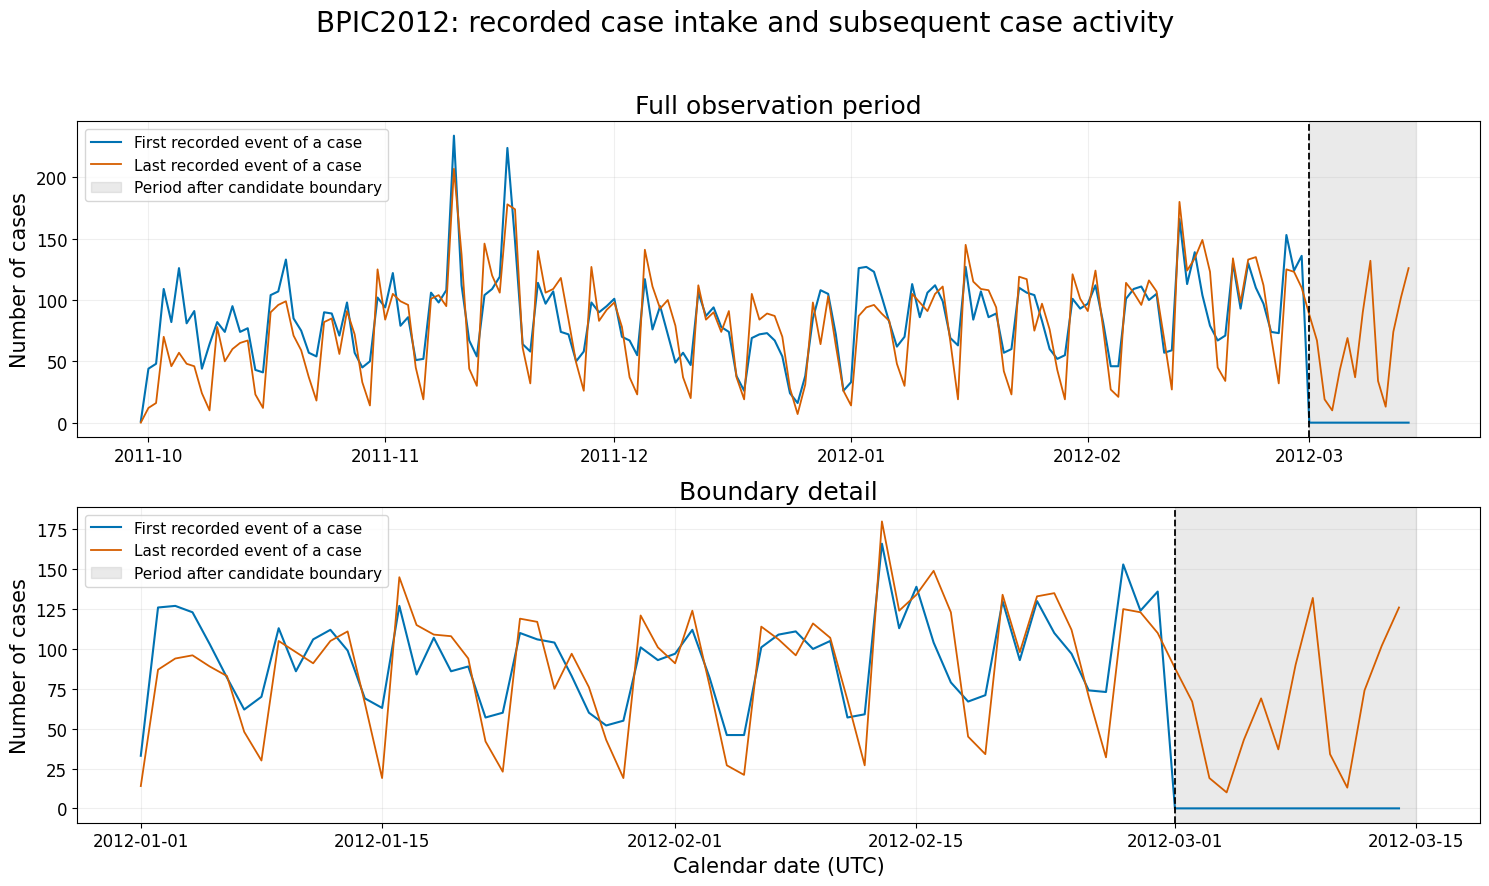

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# BPIC2012: INSPECT THE RECORDED CASE-INTAKE BOUNDARY
# Upload the ORIGINAL event log (.xes, .xes.gz, or .gz).
# No training or data restriction is performed.
# ============================================================

import io
import gzip
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

OUT_DIR = Path("/content/BPIC2012_case_intake_inspection")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Candidate boundary being investigated, not an automatic exclusion.
CANDIDATE_END = pd.Timestamp("2012-02-29", tz="UTC")
TRAILING_START = CANDIDATE_END + pd.Timedelta(days=1)

print("Upload the ORIGINAL BPIC2012 event log (.xes or .xes.gz).")
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Upload exactly one original event-log file.")

filename, content = next(iter(uploaded.items()))

if filename.lower().endswith(".gz"):
    stream = gzip.GzipFile(fileobj=io.BytesIO(content), mode="rb")
elif filename.lower().endswith(".xes"):
    stream = io.BytesIO(content)
else:
    raise ValueError("Upload an .xes or gzip-compressed .xes file.")


def local_tag(element):
    return element.tag.rsplit("}", 1)[-1]


# ============================================================
# 1. EXTRACT EACH CASE'S FIRST AND LAST RECORDED EVENT
# ============================================================

case_rows = []

for event_type, element in ET.iterparse(
    stream, events=("start", "end")
):
    if event_type == "start" and local_tag(element) == "log":
        log_root = element

    if event_type != "end" or local_tag(element) != "trace":
        continue

    case_id = None
    timestamps = []

    for child in element:
        if local_tag(child) == "event":
            for attribute in child:
                if attribute.attrib.get("key") == "time:timestamp":
                    timestamps.append(attribute.attrib.get("value"))
        elif child.attrib.get("key") == "concept:name":
            case_id = child.attrib.get("value")

    if timestamps:
        parsed = pd.to_datetime(
            timestamps,
            utc=True,
            errors="coerce",
            format="mixed",
        )

        if parsed.isna().any():
            raise ValueError(
                f"An event timestamp could not be parsed for case {case_id}."
            )

        case_rows.append({
            "case_id": case_id,
            "first_event": parsed.min(),
            "last_event": parsed.max(),
            "n_events": len(parsed),
        })

    element.clear()
    log_root.clear()

stream.close()

cases = pd.DataFrame(case_rows)

if cases.empty:
    raise ValueError("No cases with event timestamps were found.")

first_day = cases["first_event"].min().floor("D")
last_day = cases["last_event"].max().floor("D")

calendar = pd.date_range(first_day, last_day, freq="D")

daily = pd.DataFrame(index=calendar)
daily.index.name = "date"

daily["case_starts"] = (
    cases.groupby(cases["first_event"].dt.floor("D"))
    .size()
    .reindex(calendar, fill_value=0)
)

daily["case_last_events"] = (
    cases.groupby(cases["last_event"].dt.floor("D"))
    .size()
    .reindex(calendar, fill_value=0)
)

# Last recorded events are not assumed to be verified completions.
monthly = daily.resample("MS").sum()
monthly.index.name = "month"

print(f"\nCases inspected: {len(cases):,}")
print(f"Events inspected: {cases['n_events'].sum():,}")
print(f"First recorded event: {cases['first_event'].min()}")
print(f"Last recorded case start: {cases['first_event'].max()}")
print(f"Last recorded event: {cases['last_event'].max()}")

print("\nMonthly recorded case starts and last events:")
display(monthly)


# ============================================================
# 2. CHECK THE CANDIDATE BOUNDARY
# ============================================================

tail = daily.loc[daily.index >= TRAILING_START]

n_tail_starts = int(tail["case_starts"].sum())
n_tail_last_events = int(tail["case_last_events"].sum())

print(f"\nCandidate last evaluation day: {CANDIDATE_END.date()}")
print(f"Trailing calendar days: {len(tail)}")
print(f"Case starts during the trailing period: {n_tail_starts}")
print(
    "Cases with their last recorded event during the trailing period: "
    f"{n_tail_last_events:,}"
)

if len(tail) > 0 and n_tail_starts == 0:
    print(
        "\nOBSERVATION: recorded case intake stops before the log ends, "
        "while events from previously started cases continue."
    )
else:
    print(
        "\nThe candidate boundary does not isolate a nonempty period "
        "without new recorded case starts."
    )

print(
    "\nINTERPRETATION: this checks the observed arrival boundary. "
    "It does not establish why intake stops or prove that the "
    "trailing observations are invalid."
)


# ============================================================
# 3. PLOT THE FULL PERIOD AND A CLOSER VIEW OF THE BOUNDARY
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

for ax, zoom in zip(axes, [False, True]):
    view = (
        daily.loc[daily.index >= TRAILING_START - pd.Timedelta(days=60)]
        if zoom else daily
    )

    ax.plot(
        view.index,
        view["case_starts"],
        color="#0072B2",
        linewidth=1.5,
        label="First recorded event of a case",
    )
    ax.plot(
        view.index,
        view["case_last_events"],
        color="#D55E00",
        linewidth=1.3,
        label="Last recorded event of a case",
    )

    if len(tail) > 0:
        ax.axvspan(
            TRAILING_START,
            last_day + pd.Timedelta(days=1),
            color="#999999",
            alpha=0.20,
            label="Period after candidate boundary",
        )

    ax.axvline(
        TRAILING_START,
        color="black",
        linestyle="--",
        linewidth=1.3,
    )
    ax.set_title(
        "Boundary detail" if zoom else "Full observation period",
        fontsize=18,
    )
    ax.set_ylabel("Number of cases", fontsize=15)
    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.20)
    ax.legend(fontsize=11)

axes[-1].set_xlabel("Calendar date (UTC)", fontsize=15)

fig.suptitle(
    "BPIC2012: recorded case intake and subsequent case activity",
    fontsize=20,
)
fig.tight_layout(rect=[0, 0, 1, 0.95])

for extension in ["png", "pdf"]:
    fig.savefig(
        OUT_DIR / f"BPIC2012_case_intake_boundary.{extension}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()
plt.close(fig)


# ============================================================
# 4. SAVE AND DOWNLOAD THE INSPECTION
# ============================================================

cases.to_csv(OUT_DIR / "case_first_and_last_events.csv", index=False)
daily.to_csv(OUT_DIR / "daily_case_starts_and_last_events.csv")
monthly.to_csv(OUT_DIR / "monthly_case_starts_and_last_events.csv")

pd.DataFrame([{
    "candidate_last_evaluation_day": CANDIDATE_END.date(),
    "last_recorded_case_start": cases["first_event"].max(),
    "last_recorded_event": cases["last_event"].max(),
    "trailing_days": len(tail),
    "trailing_case_starts": n_tail_starts,
    "trailing_case_last_events": n_tail_last_events,
}]).to_csv(OUT_DIR / "boundary_inspection_summary.csv", index=False)

zip_path = Path("/content/BPIC2012_case_intake_inspection.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, arcname=path.name)

files.download(str(zip_path))

In [ ]:
import io
import json
import shutil
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

warnings.filterwarnings(
    "ignore",
    category=pd.errors.PerformanceWarning,
)

uploaded = files.upload()
csv_candidates = [
    name for name in uploaded
    if name.lower().endswith(".csv")
]

if len(csv_candidates) != 1:
    raise ValueError("Upload exactly one cutoff-safe daily CSV.")

csv_path = csv_candidates[0]

if "cutoff_safe" not in csv_path.lower():
    raise ValueError("Upload the regenerated cutoff-safe daily CSV.")

df = pd.read_csv(io.BytesIO(uploaded[csv_path]))

if "date" not in df.columns:
    raise ValueError("The daily CSV must contain a date column.")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

if df["date"].isna().any():
    raise ValueError("The date column contains invalid values.")

df = df.set_index("date").sort_index()
df.index = pd.DatetimeIndex(df.index).normalize()

if df.index.has_duplicates:
    raise ValueError("The daily dataset contains duplicate dates.")

expected_dates = pd.date_range(
    df.index.min(),
    df.index.max(),
    freq="D",
)

if not df.index.equals(expected_dates):
    raise ValueError("The daily series must have one row per calendar day.")

EVALUATION_END = pd.Timestamp("2012-02-29")
df_full_observation = df.copy()

df = df_full_observation.loc[
    df_full_observation.index
    < EVALUATION_END + pd.Timedelta(days=1)
].copy()

if df.empty:
    raise ValueError("The evaluation restriction removed every row.")

PROCESS_STATE_VARS = [
    "Cases_With_Activity",
    "Events_During_Day",
    "Transitions_Completed_During_Day",
    "Active_Resources_During_Day",
]

required_columns = [
    "Avg_Elapsed_Time",
    "Avg_Remaining_Time",
] + PROCESS_STATE_VARS

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print(
    f"Full observation period: "
    f"{df_full_observation.index.min().date()} to "
    f"{df_full_observation.index.max().date()} "
    f"({len(df_full_observation)} rows)"
)
print(
    f"Restricted evaluation period: "
    f"{df.index.min().date()} to {df.index.max().date()} "
    f"({len(df)} rows)"
)
print(
    f"Trailing daily rows excluded: "
    f"{len(df_full_observation) - len(df)}"
)

n_test = int(len(df) * 0.20)
df_test_final = df.tail(n_test).copy()
df_train_full = df.iloc[:-n_test].copy()

FEATURE_GROUPS = {}


def feature_engineering(
    df,
    target_var,
    horizon=1,
    target_lags=range(1, 8),
    actor_lags=range(1, 8),
    rolling_windows=(3, 7, 14),
    smooth_window=3,
):
    global FEATURE_GROUPS

    if target_var not in {
        "Avg_Elapsed_Time",
        "Avg_Remaining_Time",
    }:
        raise ValueError(f"Unsupported target: {target_var}")

    if not isinstance(horizon, (int, np.integer)) or horizon < 1:
        raise ValueError("horizon must be a positive integer.")

    df_model = df.copy()

    target_values = pd.to_numeric(
        df[target_var],
        errors="coerce",
    ).to_numpy(dtype=float)

    future_values = np.full(len(target_values), np.nan)

    if horizon < len(target_values):
        future_values[:-horizon] = target_values[horizon:]

    performance_features = []
    workload_features = []
    behavior_proportion_features = []
    behavior_count_features = []
    behavior_duration_features = []

    def add_history_features(
        series_name,
        family,
        include_current=False,
        lags=target_lags,
    ):
        columns = []

        if series_name not in df_model.columns:
            return columns

        series = pd.to_numeric(
            df_model[series_name],
            errors="coerce",
        )

        if include_current:
            columns.append(series_name)

        for lag in lags:
            name = f"{series_name}_lag{lag}"
            df_model[name] = series.shift(lag)
            columns.append(name)

        for window in rolling_windows:
            rolling = series.rolling(window)

            for statistic in ("mean", "std", "max"):
                name = f"{series_name}_rolling_{statistic}{window}"
                df_model[name] = getattr(
                    rolling,
                    statistic,
                )().shift(1)
                columns.append(name)

        mean7 = f"{series_name}_rolling_mean7"
        std7 = f"{series_name}_rolling_std7"

        if mean7 in df_model.columns and std7 in df_model.columns:
            name = f"{series_name}_zscore7"
            df_model[name] = (
                series.shift(1) - df_model[mean7]
            ) / df_model[std7]
            columns.append(name)

        return columns

    performance_features += add_history_features(
        "Avg_Elapsed_Time",
        "performance",
        include_current=False,
    )

    for variable in PROCESS_STATE_VARS:
        df_model[variable] = pd.to_numeric(
            df_model[variable],
            errors="coerce",
        )
        workload_features += add_history_features(
            variable,
            "workload",
            include_current=True,
        )

    count_variables = sorted(
        column for column in df.columns
        if column.startswith("Cum_Count_")
    )

    duration_variables = sorted(
        column for column in df.columns
        if column.startswith("Cum_Time_")
        and column.endswith("_seconds")
    )

    count_matrix = pd.DataFrame(
        {
            column: pd.to_numeric(
                df[column],
                errors="coerce",
            ).to_numpy(dtype=float)
            for column in count_variables
        },
        index=df.index,
    )

    total_count = (
        count_matrix.sum(axis=1)
        if count_variables
        else pd.Series(0.0, index=df.index)
    )

    for variable in count_variables:
        behavior = variable[len("Cum_Count_"):]
        proportion_name = f"Behavior_Proportion_{behavior}"

        df_model[proportion_name] = (
            count_matrix[variable]
            .div(total_count.replace(0, np.nan))
            .fillna(0.0)
        )

        behavior_proportion_features += add_history_features(
            proportion_name,
            "proportion",
            include_current=True,
            lags=actor_lags,
        )

        behavior_count_features += add_history_features(
            variable,
            "count",
            include_current=True,
            lags=actor_lags,
        )

    for variable in duration_variables:
        df_model[variable] = pd.to_numeric(
            df_model[variable],
            errors="coerce",
        )
        behavior_duration_features += add_history_features(
            variable,
            "duration",
            include_current=True,
            lags=actor_lags,
        )

    def unique(values):
        return list(dict.fromkeys(values))

    performance_features = unique(performance_features)
    workload_features = unique(workload_features)
    behavior_proportion_features = unique(
        behavior_proportion_features
    )
    behavior_count_features = unique(behavior_count_features)
    behavior_duration_features = unique(
        behavior_duration_features
    )

    actor_features = unique(
        behavior_proportion_features
        + behavior_count_features
        + behavior_duration_features
    )

    FEATURE_GROUPS = {
        "performance": performance_features,
        "workload": workload_features,
        "proportions": behavior_proportion_features,
        "counts": behavior_count_features,
        "durations": behavior_duration_features,
        "actor_behavior": actor_features,
    }

    df_model["target"] = future_values

    valid_positions = np.flatnonzero(
        np.isfinite(future_values)
    )
    df_model = df_model.iloc[valid_positions].copy()

    if len(df_model) != len(valid_positions):
        raise RuntimeError(
            "Unexpected dataframe filtering. "
            "Restart the runtime without cudf.pandas acceleration."
        )

    return (
        df_model,
        performance_features,
        unique(workload_features + actor_features),
    )


ARTIFACT_ROOT = Path("/content/direct_prediction_artifacts")
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)

for subdirectory in [
    "models", "predictions", "design_matrices", "metrics"
]:
    (ARTIFACT_ROOT / subdirectory).mkdir(exist_ok=True)

raw_input = df.copy()
raw_input.to_csv(
    ARTIFACT_ROOT / "input_daily_timeseries.csv",
    index_label="date",
)

pd.DataFrame({
    "date": df.index,
    "partition": [
        "train" if i < len(df_train_full) else "holdout"
        for i in range(len(df))
    ],
}).to_csv(
    ARTIFACT_ROOT / "chronological_split.csv",
    index=False,
)

run_config = {
    "targets": ["Avg_Elapsed_Time", "Avg_Remaining_Time"],
    "horizons_days": [1, 3, 7],
    "target_mode": "direct future KPI level y[t+h]",
    "evaluation": (
        "Expanding windows: 70/10, 80/10, 90/10; "
        "three non-overlapping test blocks"
    ),
    "source_notebook": "ExtensionMLP4PM",
    "input_csv": csv_path,
    "feature_variants": [
        "Performance-only", "Workload-aware", "Workload+Actor"
    ],
    "evaluation_period": {
        "analysis": "exploratory recorded case-intake period",
        "last_included_day": str(EVALUATION_END.date()),
        "full_daily_rows": len(df_full_observation),
        "retained_daily_rows": len(df),
        "target_labels": "unchanged; calculated using the full log",
    },
}

(ARTIFACT_ROOT / "run_config.json").write_text(
    json.dumps(run_config, indent=2)
)


def run_primary_rolling_evaluation(ROLL_GROUP):
    from sklearn.metrics import (
        mean_squared_error,
        mean_absolute_error,
        r2_score,
    )

    if ROLL_GROUP not in {"classical", "tree", "deep"}:
        raise ValueError(
            "ROLL_GROUP must be classical, tree, or deep."
        )

    if ROLL_GROUP == "classical":
        for name in [
            "fit_predict_sarimax",
            "fit_predict_arx_hac",
        ]:
            if not callable(globals().get(name)):
                raise RuntimeError(
                    f"Run the classical helper cell first: {name}"
                )

    if ROLL_GROUP == "tree":
        from xgboost import XGBRegressor
        from lightgbm import LGBMRegressor

        for name in ["best_xgb_params", "best_lgbm_params"]:
            if name not in globals():
                raise RuntimeError(
                    f"Run the tree settings cell first: {name}"
                )

    if ROLL_GROUP == "deep":
        for name in [
            "final_evaluate_rnn_for_target_horizon",
            "final_evaluate_rnn_with_attention",
        ]:
            if not callable(globals().get(name)):
                raise RuntimeError(
                    f"Run the recurrent helper cell first: {name}"
                )
        if "TIME_STEPS" not in globals():
            raise RuntimeError("TIME_STEPS is not defined.")

    ROLL_ROOT = (
        ARTIFACT_ROOT / "rolling_origin_evaluation" / ROLL_GROUP
    )

    for subdirectory in [
        "metrics", "predictions", "models",
        "design_matrices", "sequences", "shap",
    ]:
        (ROLL_ROOT / subdirectory).mkdir(
            parents=True,
            exist_ok=True,
        )

    ROLL_SPECS = [
        ("fold_70_10", 0.70, 0.80),
        ("fold_80_10", 0.80, 0.90),
        ("fold_90_10", 0.90, 1.00),
    ]
    ROLL_TARGETS = [
        "Avg_Elapsed_Time",
        "Avg_Remaining_Time",
    ]
    ROLL_HORIZONS = [1, 3, 7]
    ROLL_VARIANTS = {
        "PerformanceOnly": "baseline",
        "WorkloadAware": "workload",
        "WorkloadPlusActor": "actor",
    }

    metric_rows = []

    def roll_scores(y_true, y_pred, training_values):
        y_true = np.asarray(y_true, dtype=float).ravel()
        y_pred = np.asarray(y_pred, dtype=float).ravel()
        training_values = np.asarray(
            training_values,
            dtype=float,
        )

        scale = (
            np.mean(np.abs(np.diff(training_values)))
            if len(training_values) > 1 else np.nan
        )

        mae = float(mean_absolute_error(y_true, y_pred))

        return {
            "RMSE": float(
                np.sqrt(mean_squared_error(y_true, y_pred))
            ),
            "MAE": mae,
            "R2": (
                float(r2_score(y_true, y_pred))
                if len(y_true) > 1 else np.nan
            ),
            "MASE": (
                float(mae / scale)
                if np.isfinite(scale) and scale > 0
                else np.nan
            ),
        }

    def feature_screen(
        X_train,
        y_train,
        X_test,
        max_features=25,
    ):
        from sklearn.impute import SimpleImputer
        from sklearn.preprocessing import StandardScaler
        from sklearn.feature_selection import f_regression

        X_train = X_train.replace(
            [np.inf, -np.inf], np.nan
        ).copy()
        X_test = X_test.replace(
            [np.inf, -np.inf], np.nan
        ).copy()

        columns = [
            c for c in X_train.columns
            if X_train[c].notna().sum() > 0
            and X_train[c].nunique(dropna=True) > 1
        ]

        if not columns:
            raise ValueError("No usable classical predictors.")

        imputer = SimpleImputer(strategy="median")
        scaler = StandardScaler()

        train_imputed = imputer.fit_transform(X_train[columns])
        test_imputed = imputer.transform(X_test[columns])

        train_scaled = pd.DataFrame(
            scaler.fit_transform(train_imputed),
            index=X_train.index,
            columns=columns,
        )
        test_scaled = pd.DataFrame(
            scaler.transform(test_imputed),
            index=X_test.index,
            columns=columns,
        )

        scores, _ = f_regression(
            train_scaled,
            np.asarray(y_train),
        )
        scores = np.nan_to_num(
            scores,
            nan=-np.inf,
            posinf=-np.inf,
            neginf=-np.inf,
        )

        selected = list(
            train_scaled.columns[
                np.argsort(scores)[::-1][
                    :min(max_features, len(columns))
                ]
            ]
        )

        return (
            train_scaled[selected],
            test_scaled[selected],
            selected,
            imputer,
            scaler,
            columns,
        )

    def save_result(
        group,
        model_name,
        fold,
        target,
        horizon,
        variant,
        origins,
        y_true,
        y_pred,
        n_train,
        training_values,
        model=None,
        design=None,
        sequence=None,
    ):
        safe_name = (
            f"{group}_{model_name}_{fold}_{target}_"
            f"h{horizon}_{variant}"
        ).replace("+", "_").replace("/", "_")

        origins = pd.Index(origins)
        y_true = np.asarray(y_true).ravel()
        y_pred = np.asarray(y_pred).ravel()

        target_dates = [
            df.index[df.index.get_loc(date) + horizon]
            for date in origins
        ]

        metric_rows.append({
            "group": group,
            "model": model_name,
            "fold": fold,
            "target": target,
            "horizon_days": horizon,
            "variant": variant,
            "n_train": int(n_train),
            "n_test": len(y_true),
            "n_train_raw": int(train_end_global),
            "n_test_origins_before_horizon_purge": int(
                test_raw_global
            ),
            **roll_scores(y_true, y_pred, training_values),
        })

        pd.DataFrame({
            "fold": fold,
            "cutoff_date": origins,
            "target_date": target_dates,
            "y_true": y_true,
            "y_pred": y_pred,
            "error": y_true - y_pred,
        }).to_csv(
            ROLL_ROOT / "predictions" / f"{safe_name}.csv",
            index=False,
        )

        if model is not None:
            joblib.dump(
                model,
                ROLL_ROOT / "models" / f"{safe_name}.joblib",
            )

        if design is not None:
            design.assign(
                target=y_true,
                prediction=y_pred,
            ).to_csv(
                ROLL_ROOT / "design_matrices"
                / f"{safe_name}.csv",
                index_label="cutoff_date",
            )

        if sequence is not None:
            np.savez_compressed(
                ROLL_ROOT / "sequences" / f"{safe_name}.npz",
                X=sequence.get(
                    "X_test_scaled",
                    sequence.get("X_test"),
                ),
                feature_names=np.asarray(
                    sequence.get(
                        "feature_names",
                        sequence.get("features", []),
                    )
                ),
                dates=np.asarray(origins.astype(str)),
                y_true=y_true,
                y_pred=y_pred,
            )

    for fold_name, train_fraction, end_fraction in ROLL_SPECS:
        train_end = int(np.floor(len(df) * train_fraction))
        test_end = int(np.floor(len(df) * end_fraction))

        print(
            f"\n{ROLL_GROUP}: {fold_name} | "
            f"training rows={train_end}, "
            f"test-block rows={test_end - train_end}"
        )

        for target_var in ROLL_TARGETS:
            for horizon in ROLL_HORIZONS:
                train_raw = df.iloc[:train_end].copy()
                test_raw = df.iloc[train_end:test_end].copy()

                if test_raw.empty:
                    continue

                train_end_global = len(train_raw)
                test_raw_global = len(test_raw)

                training_values = pd.to_numeric(
                    train_raw[target_var],
                    errors="coerce",
                ).dropna().to_numpy(dtype=float)

                if ROLL_GROUP in {"classical", "tree"}:
                    train_fe, _, _ = feature_engineering(
                        train_raw,
                        target_var=target_var,
                        horizon=horizon,
                    )
                    groups = {
                        key: list(value)
                        for key, value in FEATURE_GROUPS.items()
                    }

                    context = pd.concat([
                        train_raw.tail(200),
                        test_raw,
                    ])

                    test_fe, _, _ = feature_engineering(
                        context,
                        target_var=target_var,
                        horizon=horizon,
                    )
                    test_fe = test_fe.loc[
                        test_fe.index.isin(test_raw.index)
                    ]

                    p_features = groups["performance"]
                    w_features = (
                        p_features + groups["workload"]
                    )
                    a_features = (
                        w_features
                        + groups["proportions"]
                        + groups["counts"]
                        + groups["durations"]
                    )

                    variant_features = {
                        "PerformanceOnly": p_features,
                        "WorkloadAware": w_features,
                        "WorkloadPlusActor": a_features,
                        "ProportionsOnly": (
                            w_features + groups["proportions"]
                        ),
                        "CountsOnly": (
                            w_features + groups["counts"]
                        ),
                        "DurationsOnly": (
                            w_features + groups["durations"]
                        ),
                    }

                    for variant, features in variant_features.items():
                        if not features:
                            continue

                        if (
                            ROLL_GROUP == "classical"
                            and variant not in ROLL_VARIANTS
                        ):
                            continue

                        train_rows = train_fe.dropna(
                            subset=features + ["target"]
                        ).copy()
                        test_rows = test_fe.dropna(
                            subset=features + ["target"]
                        ).copy()

                        if len(train_rows) < 10 or test_rows.empty:
                            print(
                                f"Skip {fold_name}, {target_var}, "
                                f"h={horizon}, {variant}: "
                                f"train={len(train_rows)}, "
                                f"test={len(test_rows)}"
                            )
                            continue

                        X_train = train_rows[features]
                        X_test = test_rows[features]
                        y_train = train_rows["target"].to_numpy(
                            dtype=float
                        )
                        y_test = test_rows["target"].to_numpy(
                            dtype=float
                        )

                        if ROLL_GROUP == "classical":
                            for model_name in ["SARIMAX", "ARX-HAC"]:
                                try:
                                    (
                                        Xa, Xb, selected,
                                        imputer, scaler, input_columns,
                                    ) = feature_screen(
                                        X_train,
                                        y_train,
                                        X_test,
                                        max_features=25,
                                    )

                                    if model_name == "SARIMAX":
                                        fitted, predictions = (
                                            fit_predict_sarimax(
                                                Xa,
                                                pd.Series(y_train),
                                                Xb,
                                            )
                                        )
                                    else:
                                        fitted, predictions = (
                                            fit_predict_arx_hac(
                                                Xa,
                                                pd.Series(y_train),
                                                Xb,
                                                hac_lags=max(1, horizon),
                                            )
                                        )

                                    save_result(
                                        "Classical",
                                        model_name,
                                        fold_name,
                                        target_var,
                                        horizon,
                                        variant,
                                        test_rows.index,
                                        y_test,
                                        predictions,
                                        len(train_rows),
                                        training_values,
                                        model={
                                            "fitted_model": fitted,
                                            "selected_features": selected,
                                            "input_columns": input_columns,
                                            "imputer": imputer,
                                            "scaler": scaler,
                                            "target_mode": "direct",
                                        },
                                        design=Xb,
                                    )

                                except Exception as error:
                                    print(
                                        f"Classical skip: {model_name}, "
                                        f"{fold_name}, {target_var}, "
                                        f"h={horizon}, {variant}: {error}"
                                    )

                        if ROLL_GROUP == "tree":
                            settings = [
                                ("XGBoost", best_xgb_params),
                                ("LightGBM", best_lgbm_params),
                            ]

                            for model_name, parameters in settings:
                                if (
                                    variant not in ROLL_VARIANTS
                                    and model_name != "XGBoost"
                                ):
                                    continue

                                try:
                                    model = (
                                        XGBRegressor(**parameters)
                                        if model_name == "XGBoost"
                                        else LGBMRegressor(**parameters)
                                    )

                                    model.fit(X_train, y_train)
                                    predictions = model.predict(X_test)

                                    save_result(
                                        "Tree",
                                        model_name,
                                        fold_name,
                                        target_var,
                                        horizon,
                                        variant,
                                        test_rows.index,
                                        y_test,
                                        predictions,
                                        len(train_rows),
                                        training_values,
                                        model={
                                            "model": model,
                                            "features": list(features),
                                            "params": parameters,
                                            "target_mode": "direct",
                                        },
                                        design=X_test,
                                    )

                                    if (
                                        model_name == "XGBoost"
                                        and variant == "WorkloadPlusActor"
                                    ):
                                        try:
                                            import shap

                                            shap_values = np.asarray(
                                                shap.TreeExplainer(
                                                    model
                                                ).shap_values(X_test)
                                            )

                                            np.savez_compressed(
                                                ROLL_ROOT / "shap" / (
                                                    f"XGBoost_{fold_name}_"
                                                    f"{target_var}_"
                                                    f"h{horizon}_"
                                                    f"{variant}.npz"
                                                ),
                                                values=shap_values,
                                                feature_names=np.asarray(
                                                    features
                                                ),
                                                feature_values=(
                                                    X_test.to_numpy()
                                                ),
                                                dates=np.asarray(
                                                    test_rows.index.astype(str)
                                                ),
                                            )
                                        except Exception as error:
                                            print("SHAP skipped:", error)

                                except Exception as error:
                                    print(
                                        f"Tree skip: {model_name}, "
                                        f"{fold_name}, {target_var}, "
                                        f"h={horizon}, {variant}: {error}"
                                    )

                if ROLL_GROUP == "deep":
                    for variant, feature_set in ROLL_VARIANTS.items():
                        for rnn_type in ["lstm", "gru"]:
                            for attention in [False, True]:
                                try:
                                    evaluator = (
                                        final_evaluate_rnn_with_attention
                                        if attention
                                        else final_evaluate_rnn_for_target_horizon
                                    )

                                    result = evaluator(
                                        train_raw,
                                        test_raw,
                                        target_var=target_var,
                                        horizon=horizon,
                                        feature_set=feature_set,
                                        rnn_type=rnn_type,
                                        time_steps=TIME_STEPS,
                                        seed=42,
                                    )

                                    model_name = (
                                        f"{rnn_type.upper()}+"
                                        f"{'Attention' if attention else 'NoAttention'}"
                                    )

                                    destination = (
                                        ROLL_ROOT / "models" / (
                                            f"RNN_{model_name}_"
                                            f"{fold_name}_{target_var}_"
                                            f"h{horizon}_{variant}.keras"
                                        )
                                    )

                                    saved_model = None
                                    model_path = result.get("model_path")

                                    if (
                                        model_path
                                        and Path(model_path).exists()
                                    ):
                                        shutil.copy2(
                                            model_path,
                                            destination,
                                        )
                                        saved_model = str(destination)

                                    elif result.get("model") is not None:
                                        result["model"].save(destination)
                                        saved_model = str(destination)

                                    preprocessing_path = (
                                        ROLL_ROOT / "models" / (
                                            f"RNN_{model_name}_"
                                            f"{fold_name}_{target_var}_"
                                            f"h{horizon}_{variant}"
                                            ".preprocessing.joblib"
                                        )
                                    )

                                    joblib.dump(
                                        {
                                            "scaler_x": result.get("scaler_x"),
                                            "scaler_y": result.get("scaler_y"),
                                            "features": result.get(
                                                "feature_names",
                                                result.get("features", []),
                                            ),
                                            "time_steps": TIME_STEPS,
                                            "target": target_var,
                                            "horizon_days": horizon,
                                            "variant": variant,
                                            "fold": fold_name,
                                        },
                                        preprocessing_path,
                                    )

                                    save_result(
                                        "DeepLearning",
                                        model_name,
                                        fold_name,
                                        target_var,
                                        horizon,
                                        variant,
                                        result["index"],
                                        result["y_true"],
                                        result["y_pred"],
                                        int(result.get(
                                            "n_train_sequences",
                                            len(train_raw),
                                        )),
                                        training_values,
                                        model={
                                            "model_path": saved_model,
                                            "feature_set": feature_set,
                                            "target_mode": "direct",
                                        },
                                        sequence=result,
                                    )

                                except Exception as error:
                                    print(
                                        f"RNN skip: {rnn_type}, "
                                        f"attention={attention}, "
                                        f"{fold_name}, {target_var}, "
                                        f"h={horizon}, {variant}: {error}"
                                    )

    fold_metrics = pd.DataFrame(metric_rows)

    fold_metrics.to_csv(
        ROLL_ROOT / "metrics" / "rolling_origin_fold_metrics.csv",
        index=False,
    )

    if fold_metrics.empty:
        raise RuntimeError(
            "No metrics were produced. Inspect the errors above."
        )

    key_columns = [
        "group", "model", "target", "horizon_days", "variant"
    ]
    summary_rows = []

    for keys, group in fold_metrics.groupby(
        key_columns,
        dropna=False,
    ):
        row = dict(zip(key_columns, keys))
        row["n_folds"] = int(group["fold"].nunique())

        for metric in ["RMSE", "MAE", "R2", "MASE"]:
            values = pd.to_numeric(
                group[metric],
                errors="coerce",
            ).dropna()

            row[f"{metric}_fold_scores"] = "; ".join(
                f"{fold}:{value:.6g}"
                for fold, value in zip(
                    group.loc[values.index, "fold"],
                    values,
                )
            )

            row[f"{metric}_mean"] = (
                float(values.mean()) if len(values) else np.nan
            )
            row[f"{metric}_sd"] = (
                float(values.std(ddof=1))
                if len(values) > 1 else np.nan
            )
            row[f"{metric}_min"] = (
                float(values.min()) if len(values) else np.nan
            )
            row[f"{metric}_max"] = (
                float(values.max()) if len(values) else np.nan
            )
            row[f"{metric}_range"] = (
                float(values.max() - values.min())
                if len(values) else np.nan
            )

        summary_rows.append(row)

    summary_df = pd.DataFrame(summary_rows)

    summary_df.to_csv(
        ROLL_ROOT / "metrics"
        / "rolling_origin_across_fold_summary.csv",
        index=False,
    )

    fold_counts = (
        fold_metrics.groupby(
            [
                "fold", "group", "model", "target",
                "horizon_days", "variant",
            ],
            as_index=False,
        )
        .agg(
            n_train_min=("n_train", "min"),
            n_test_min=("n_test", "min"),
            n_test_max=("n_test", "max"),
        )
    )

    fold_counts.to_csv(
        ROLL_ROOT / "metrics"
        / "effective_sample_counts_by_fold.csv",
        index=False,
    )

    roll_config = {
        "folds": ROLL_SPECS,
        "targets": ROLL_TARGETS,
        "horizons": ROLL_HORIZONS,
        "variants": list(ROLL_VARIANTS),
        "direct_targets": True,
        "test_windows_non_overlapping": True,
        "trailing_horizon_origins_purged_from_each_test_window": True,
        "mase_scaling": (
            "Fold-specific mean absolute first difference "
            "of the training target series"
        ),
        "settings": "Existing model settings retained",
        "model_group": ROLL_GROUP,
        "evaluation_period": run_config["evaluation_period"],
    }

    (ROLL_ROOT / "run_config.json").write_text(
        json.dumps(roll_config, indent=2)
    )

    metadata_directory = ROLL_ROOT / "dataset_metadata"
    metadata_directory.mkdir(parents=True, exist_ok=True)

    for name in [
        "dataset_characteristics.csv",
        "behavior_type_distribution.csv",
        "input_daily_timeseries.csv",
        "chronological_split.csv",
        "run_config.json",
    ]:
        source = ARTIFACT_ROOT / name
        if source.exists():
            shutil.copy2(source, metadata_directory / name)

    display(fold_metrics.head(20))
    display(summary_df.head(20))

    expected_primary_rows = (
        216 if ROLL_GROUP == "deep" else 108
    )
    primary_rows = fold_metrics[
        fold_metrics["variant"].isin(ROLL_VARIANTS)
    ]

    print(
        f"\nPrimary metric rows: {len(primary_rows)} "
        f"(expected {expected_primary_rows})"
    )

    if len(primary_rows) != expected_primary_rows:
        print(
            "Some configurations are missing. "
            "Inspect the skip/error messages before combining results."
        )

    bundle = shutil.make_archive(
        str(ARTIFACT_ROOT / f"{ROLL_GROUP}_rolling_origin_results"),
        "zip",
        root_dir=ROLL_ROOT,
    )

    print(f"Saved: {ROLL_ROOT}")
    files.download(bundle)


check_input = df.iloc[:107].copy()
check_output, _, _ = feature_engineering(
    check_input,
    target_var="Avg_Elapsed_Time",
    horizon=1,
)

expected_rows = int(
    np.isfinite(
        pd.to_numeric(
            check_input["Avg_Elapsed_Time"],
            errors="coerce",
        ).to_numpy(dtype=float)[1:]
    ).sum()
)

print(
    f"\nFeature-engineering check: "
    f"{len(check_output)} rows, expected {expected_rows}"
)

if len(check_output) != expected_rows or expected_rows == 0:
    raise RuntimeError(
        "Feature-engineering check failed. Do not start training."
    )

print(
    "Evaluator available:",
    callable(run_primary_rolling_evaluation),
)
print(
    "Section 1 complete. Run the model helper/settings cells, "
    "then the corresponding training cells."
)

Saving BPIC2012_final_online_daily_time_series_cutoff_safe.csv to BPIC2012_final_online_daily_time_series_cutoff_safe.csv
Full observation period: 2011-09-30 to 2012-03-14 (167 rows)
Restricted evaluation period: 2011-09-30 to 2012-02-29 (153 rows)
Trailing daily rows excluded: 14

Feature-engineering check: 106 rows, expected 106
Evaluator available: True
Section 1 complete. Run the model helper/settings cells, then the corresponding training cells.


## 1.1 Dataset characteristics for the manuscript

Run this after loading the daily CSV. When prompted, upload the matching raw event log (`.xes`, `.xes.gz`, or a ZIP containing one XES file) and the exact enriched actor-behavior CSV used to generate the daily series. This reports the calendar span, daily observations, resource coverage, and behavior-class distribution. Effective training and test counts after feature and horizon filtering are saved by the rolling-origin run cell in each model section.


In [ ]:
# DATASET CHARACTERISTICS: raw log + behavior table
import os, sys, zipfile, subprocess, importlib.util
from pathlib import Path
from google.colab import files

if importlib.util.find_spec("pm4py") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pm4py"])
import pm4py

print("Upload the raw event log (XES, XES.GZ, or ZIP).")
raw_upload = files.upload()
raw_names = list(raw_upload)
meta_logs = [n for n in raw_names if n.lower().endswith((".xes", ".xes.gz", ".zip"))]
if len(meta_logs) != 1:
    raise ValueError("Upload exactly one raw XES, XES.GZ, or ZIP file in this step.")
meta_log_path = meta_logs[0]

print("Upload the enriched actor-behavior CSV.")
behavior_upload = files.upload()
behavior_names = list(behavior_upload)
meta_csvs = [n for n in behavior_names if n.lower().endswith(".csv")]
if len(meta_csvs) != 1:
    raise ValueError("Upload exactly one enriched actor-behavior CSV in this step.")

if meta_log_path.lower().endswith(".zip"):
    with zipfile.ZipFile(meta_log_path) as zf:
        xes_names = [
            n for n in zf.namelist()
            if n.lower().endswith((".xes", ".xes.gz"))
        ]
        if len(xes_names) != 1:
            raise ValueError("The ZIP must contain exactly one XES or XES.GZ file.")
        Path("/content/metadata_raw_log").mkdir(parents=True, exist_ok=True)
        meta_log_path = zf.extract(xes_names[0], "/content/metadata_raw_log")

log_meta = pm4py.read_xes(meta_log_path)
events_meta = pm4py.convert_to_dataframe(log_meta)
actor_meta = pd.read_csv(meta_csvs[0], low_memory=False)

resource_candidates = [
    c for c in ["org:resource", "org:group"]
    if c in events_meta.columns
]
resource_col_meta = resource_candidates[0] if resource_candidates else None
missing_resource_fraction = (
    float(events_meta[resource_col_meta].isna().mean())
    if resource_col_meta else np.nan
)
resource_count = (
    int(events_meta[resource_col_meta].nunique(dropna=True))
    if resource_col_meta else np.nan
)

behavior_col = "behavior" if "behavior" in actor_meta.columns else None
behavior_distribution = (
    actor_meta[behavior_col].fillna("<missing>").value_counts(dropna=False)
    .rename_axis("behavior").reset_index(name="transition_count")
    if behavior_col
    else pd.DataFrame(columns=["behavior", "transition_count"])
)

dataset_characteristics = pd.DataFrame([{
    "dataset_file": Path(csv_path).name,
    "calendar_start": df.index.min().date(),
    "calendar_end": df.index.max().date(),
    "daily_observations": int(len(df)),
    "raw_event_rows": int(len(events_meta)),
    "resource_column": resource_col_meta,
    "distinct_resources_or_groups": resource_count,
    "missing_resource_fraction": missing_resource_fraction,
    "behavior_table_rows": int(len(actor_meta)),
    "behavior_labels": (
        ", ".join(sorted(actor_meta[behavior_col].dropna().astype(str).unique()))
        if behavior_col else "unavailable"
    )
}])

display(dataset_characteristics)
display(behavior_distribution)
dataset_characteristics.to_csv(
    ARTIFACT_ROOT / "dataset_characteristics.csv", index=False
)
behavior_distribution.to_csv(
    ARTIFACT_ROOT / "behavior_type_distribution.csv", index=False
)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Upload the raw event log (XES, XES.GZ, or ZIP).


Saving BPI_Challenge_2012.xes.gz to BPI_Challenge_2012.xes.gz
Upload the enriched actor-behavior CSV.


Saving BPIC2012_actor_behavior_results.csv to BPIC2012_actor_behavior_results.csv


/usr/local/lib/python3.13/dist-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


parsing log, completed traces ::   0%|          | 0/13087 [00:00<?, ?it/s]

,dataset_file,calendar_start,calendar_end,daily_observations,raw_event_rows,resource_column,distinct_resources_or_groups,missing_resource_fraction,behavior_table_rows,behavior_labels
0,BPIC2012_final_online_daily_time_series_cutoff...,2011-09-30,2012-02-29,153,262200,org:resource,68,0.068688,230839,"C, HB, HI, I"


,behavior,transition_count
0,C,171286
1,HB,41130
2,HI,10576
3,I,7847


# 2. Classical time-series models

Run after Section 1. The helper cell defines SARIMAX and ARX-HAC. The next code cell trains both models on the three expanding-window blocks and downloads reusable results.


In [ ]:
# CLASSICAL MODEL HELPERS FOR ROLLING-ORIGIN EVALUATION
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
SARIMAX_ORDER=(1,0,0)
SARIMAX_SEASONAL_ORDER=(1,0,0,7)
def fit_predict_sarimax(X_train, y_train, X_test):
    Xtr, Xte = np.asarray(X_train, float), np.asarray(X_test, float)
    ytr = np.asarray(y_train, float).ravel()
    fit = SARIMAX(ytr, exog=Xtr, order=SARIMAX_ORDER,
                  seasonal_order=SARIMAX_SEASONAL_ORDER, trend="c",
                  enforce_stationarity=False, enforce_invertibility=False
                  ).fit(disp=False, maxiter=300)
    return fit, pd.Series(np.asarray(fit.forecast(len(Xte), exog=Xte)).ravel())

def fit_predict_arx_hac(X_train, y_train, X_test, hac_lags=7):
    Xtr = sm.add_constant(np.asarray(X_train, float), has_constant="add")
    Xte = sm.add_constant(np.asarray(X_test, float), has_constant="add")
    ytr = np.asarray(y_train, float).ravel()
    fit = sm.OLS(ytr, Xtr).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
    return fit, pd.Series(np.asarray(fit.predict(Xte)).ravel())

The next cell trains both classical models on the three expanding-window blocks and downloads their rolling-origin results bundle.


In [ ]:
run_primary_rolling_evaluation("classical")



classical: fold_70_10 | training rows=107, test-block rows=15


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/tmp/ipykernel_3331/284874165.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit = sm.OLS(ytr, Xtr).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/tmp/ipykernel_3331/284874165.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit = sm.OLS(ytr, Xtr).fit(cov_ty


classical: fold_80_10 | training rows=122, test-block rows=15


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/tmp/ipykernel_3331/284874165.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit = sm.OLS(ytr, Xtr).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/tmp/ipykernel_3331/284874165.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit = sm.OLS(ytr, Xtr).fit(cov_ty


classical: fold_90_10 | training rows=137, test-block rows=16


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/tmp/ipykernel_3331/284874165.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit = sm.OLS(ytr, Xtr).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/tmp/ipykernel_3331/284874165.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit = sm.OLS(ytr, Xtr).fit(cov_ty

,group,model,fold,target,horizon_days,variant,n_train,n_test,n_train_raw,n_test_origins_before_horizon_purge,RMSE,MAE,R2,MASE
0,Classical,SARIMAX,fold_70_10,Avg_Elapsed_Time,1,PerformanceOnly,92,14,107,15,50.205140,43.683030,0.408721,0.770476
1,Classical,ARX-HAC,fold_70_10,Avg_Elapsed_Time,1,PerformanceOnly,92,14,107,15,51.126620,44.130119,0.386816,0.778362
2,Classical,SARIMAX,fold_70_10,Avg_Elapsed_Time,1,WorkloadAware,92,14,107,15,56.725573,48.037298,0.245161,0.847276
3,Classical,ARX-HAC,fold_70_10,Avg_Elapsed_Time,1,WorkloadAware,92,14,107,15,50.196021,41.523679,0.408935,0.732390
4,Classical,SARIMAX,fold_70_10,Avg_Elapsed_Time,1,WorkloadPlusActor,92,14,107,15,59.511832,48.816601,0.169188,0.861021
5,Classical,ARX-HAC,fold_70_10,Avg_Elapsed_Time,1,WorkloadPlusActor,92,14,107,15,52.225991,41.134096,0.360163,0.725518
6,Classical,SARIMAX,fold_70_10,Avg_Elapsed_Time,3,PerformanceOnly,90,12,107,15,50.374123,40.714422,0.468143,0.718116
7,Classical,ARX-HAC,fold_70_10,Avg_Elapsed_Time,3,PerformanceOnly,90,12,107,15,52.178960,43.535862,0.429348,0.767880
8,Classical,SARIMAX,fold_70_10,Avg_Elapsed_Time,3,WorkloadAware,90,12,107,15,62.101008,51.067786,0.191691,0.900727
9,Classical,ARX-HAC,fold_70_10,Avg_Elapsed_Time,3,WorkloadAware,90,12,107,15,60.151430,48.107187,0.241646,0.848509


,group,model,target,horizon_days,variant,n_folds,RMSE_fold_scores,RMSE_mean,RMSE_sd,RMSE_min,...,R2_sd,R2_min,R2_max,R2_range,MASE_fold_scores,MASE_mean,MASE_sd,MASE_min,MASE_max,MASE_range
0,Classical,ARX-HAC,Avg_Elapsed_Time,1,PerformanceOnly,3,fold_70_10:51.1266; fold_80_10:33.9998; fold_9...,41.128037,8.916907,33.999783,...,0.126034,0.386816,0.637650,0.250834,fold_70_10:0.778362; fold_80_10:0.4637; fold_9...,0.594348,0.163978,0.463700,0.778362,0.314662
1,Classical,ARX-HAC,Avg_Elapsed_Time,1,WorkloadAware,3,fold_70_10:50.196; fold_80_10:43.1407; fold_90...,56.644495,17.635565,43.140731,...,0.739872,-0.868700,0.416621,1.285321,fold_70_10:0.73239; fold_80_10:0.597862; fold_...,0.808130,0.256661,0.597862,1.094139,0.496276
2,Classical,ARX-HAC,Avg_Elapsed_Time,1,WorkloadPlusActor,3,fold_70_10:52.226; fold_80_10:34.548; fold_90_...,43.228216,8.843272,34.548002,...,0.140558,0.360163,0.625871,0.265708,fold_70_10:0.725518; fold_80_10:0.480017; fold...,0.593824,0.123724,0.480017,0.725518,0.245501
3,Classical,ARX-HAC,Avg_Elapsed_Time,3,PerformanceOnly,3,fold_70_10:52.179; fold_80_10:36.2951; fold_90...,42.516378,8.482699,36.295098,...,0.098357,0.429348,0.622263,0.192914,fold_70_10:0.76788; fold_80_10:0.490104; fold_...,0.615837,0.140745,0.490104,0.767880,0.277776
4,Classical,ARX-HAC,Avg_Elapsed_Time,3,WorkloadAware,3,fold_70_10:60.1514; fold_80_10:41.8767; fold_9...,53.982391,10.484442,41.876744,...,0.266995,-0.036679,0.497149,0.533828,fold_70_10:0.848509; fold_80_10:0.634921; fold...,0.806997,0.155531,0.634921,0.937560,0.302639
5,Classical,ARX-HAC,Avg_Elapsed_Time,3,WorkloadPlusActor,3,fold_70_10:66.562; fold_80_10:33.5726; fold_90...,45.675147,18.164461,33.572623,...,0.331238,0.071391,0.676805,0.605414,fold_70_10:0.920674; fold_80_10:0.494399; fold...,0.650838,0.234673,0.494399,0.920674,0.426274
6,Classical,ARX-HAC,Avg_Elapsed_Time,7,PerformanceOnly,3,fold_70_10:62.6536; fold_80_10:19.8132; fold_9...,40.221269,21.491809,19.813215,...,0.236705,0.374803,0.813130,0.438326,fold_70_10:0.997543; fold_80_10:0.293749; fold...,0.611281,0.356895,0.293749,0.997543,0.703794
7,Classical,ARX-HAC,Avg_Elapsed_Time,7,WorkloadAware,3,fold_70_10:63.2853; fold_80_10:36.2287; fold_9...,50.994703,13.697132,36.228675,...,0.362709,-0.225124,0.427709,0.652833,fold_70_10:0.881046; fold_80_10:0.528744; fold...,0.728278,0.180747,0.528744,0.881046,0.352302
8,Classical,ARX-HAC,Avg_Elapsed_Time,7,WorkloadPlusActor,3,fold_70_10:66.9882; fold_80_10:39.0886; fold_9...,44.458129,20.382887,27.297518,...,0.215070,0.272670,0.680696,0.408026,fold_70_10:1.0189; fold_80_10:0.506435; fold_9...,0.645876,0.326461,0.412290,1.018902,0.606611
9,Classical,ARX-HAC,Avg_Remaining_Time,1,PerformanceOnly,3,fold_70_10:21.2017; fold_80_10:38.7958; fold_9...,50.139539,35.976954,21.201716,...,4.476459,-7.931164,0.495046,8.426210,fold_70_10:0.397107; fold_80_10:0.671669; fold...,1.050357,0.904168,0.397107,2.082296,1.685189



Primary metric rows: 108 (expected 108)
Saved: /content/direct_prediction_artifacts/rolling_origin_evaluation/classical


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 3. Tree-based models

Run after Section 1. The settings cell defines the fixed XGBoost and LightGBM parameters. The rolling-origin cell trains all three input variants and saves XGBoost SHAP values for WorkloadPlusActor.


In [ ]:
# FIXED TREE-MODEL SETTINGS FOR ROLLING-ORIGIN EVALUATION
best_xgb_params={"n_estimators":1500,"learning_rate":0.2,"max_depth":3,
    "subsample":0.9,"colsample_bytree":0.9,"gamma":0,"min_child_weight":1,"random_state":42}
best_lgbm_params={"n_estimators":1500,"learning_rate":0.05,"max_depth":5,
    "bagging_fraction":0.9,"feature_fraction":0.9,"reg_alpha":0,"reg_lambda":0,
    "min_child_samples":1,"random_state":42}


The rolling-origin evaluator trains XGBoost and LightGBM for all three variants and saves fold predictions, models, design matrices, and XGBoost SHAP values for WorkloadPlusActor.


The next cell trains the tree models on the three expanding-window blocks and downloads their results bundle.


In [ ]:
run_primary_rolling_evaluation("tree")


Streaming output truncated to the last 5000 lines.
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posit

,group,model,fold,target,horizon_days,variant,n_train,n_test,n_train_raw,n_test_origins_before_horizon_purge,RMSE,MAE,R2,MASE
0,Tree,XGBoost,fold_70_10,Avg_Elapsed_Time,1,PerformanceOnly,92,14,107,15,48.125886,39.610913,0.456682,0.698653
1,Tree,LightGBM,fold_70_10,Avg_Elapsed_Time,1,PerformanceOnly,92,14,107,15,44.852540,36.780242,0.528078,0.648725
2,Tree,XGBoost,fold_70_10,Avg_Elapsed_Time,1,WorkloadAware,92,14,107,15,46.743888,37.532835,0.487439,0.662000
3,Tree,LightGBM,fold_70_10,Avg_Elapsed_Time,1,WorkloadAware,92,14,107,15,40.122775,35.283968,0.622360,0.622334
4,Tree,XGBoost,fold_70_10,Avg_Elapsed_Time,1,WorkloadPlusActor,92,14,107,15,41.842123,34.567570,0.589301,0.609699
5,Tree,LightGBM,fold_70_10,Avg_Elapsed_Time,1,WorkloadPlusActor,92,14,107,15,48.688404,34.337442,0.443907,0.605640
6,Tree,XGBoost,fold_70_10,Avg_Elapsed_Time,1,ProportionsOnly,92,14,107,15,46.543792,38.449571,0.491817,0.678169
7,Tree,XGBoost,fold_70_10,Avg_Elapsed_Time,1,CountsOnly,92,14,107,15,49.887886,40.685685,0.416170,0.717609
8,Tree,XGBoost,fold_70_10,Avg_Elapsed_Time,1,DurationsOnly,92,14,107,15,48.989102,38.895000,0.437017,0.686025
9,Tree,XGBoost,fold_70_10,Avg_Elapsed_Time,3,PerformanceOnly,90,12,107,15,51.884925,44.791498,0.435762,0.790027


,group,model,target,horizon_days,variant,n_folds,RMSE_fold_scores,RMSE_mean,RMSE_sd,RMSE_min,...,R2_sd,R2_min,R2_max,R2_range,MASE_fold_scores,MASE_mean,MASE_sd,MASE_min,MASE_max,MASE_range
0,Tree,LightGBM,Avg_Elapsed_Time,1,PerformanceOnly,3,fold_70_10:44.8525; fold_80_10:34.5077; fold_9...,35.057995,9.531319,25.813746,...,0.131084,0.528078,0.787763,0.259685,fold_70_10:0.648725; fold_80_10:0.551533; fold...,0.524558,0.139623,0.373415,0.648725,0.275310
1,Tree,LightGBM,Avg_Elapsed_Time,1,WorkloadAware,3,fold_70_10:40.1228; fold_80_10:32.7993; fold_9...,38.015242,4.544763,32.799313,...,0.106561,0.461356,0.662786,0.201431,fold_70_10:0.622334; fold_80_10:0.493989; fold...,0.548628,0.066263,0.493989,0.622334,0.128346
2,Tree,LightGBM,Avg_Elapsed_Time,1,WorkloadPlusActor,3,fold_70_10:48.6884; fold_80_10:34.0133; fold_9...,39.926393,7.741251,34.013282,...,0.097521,0.443907,0.637362,0.193455,fold_70_10:0.60564; fold_80_10:0.424257; fold_...,0.507909,0.091507,0.424257,0.605640,0.181383
3,Tree,LightGBM,Avg_Elapsed_Time,3,PerformanceOnly,3,fold_70_10:55.7774; fold_80_10:43.8475; fold_9...,45.778214,9.187250,37.709743,...,0.121284,0.347927,0.589397,0.241470,fold_70_10:0.788882; fold_80_10:0.613368; fold...,0.658432,0.114758,0.573045,0.788882,0.215837
4,Tree,LightGBM,Avg_Elapsed_Time,3,WorkloadAware,3,fold_70_10:58.0858; fold_80_10:34.0571; fold_9...,43.804508,12.639658,34.057130,...,0.192172,0.292837,0.667409,0.374573,fold_70_10:0.924247; fold_80_10:0.488167; fold...,0.642971,0.244004,0.488167,0.924247,0.436081
5,Tree,LightGBM,Avg_Elapsed_Time,3,WorkloadPlusActor,3,fold_70_10:59.6288; fold_80_10:35.5866; fold_9...,42.641896,14.781236,32.710276,...,0.237797,0.254766,0.691053,0.436287,fold_70_10:0.797017; fold_80_10:0.536005; fold...,0.602445,0.171304,0.474315,0.797017,0.322702
6,Tree,LightGBM,Avg_Elapsed_Time,7,PerformanceOnly,3,fold_70_10:72.3757; fold_80_10:24.1936; fold_9...,44.553876,24.942654,24.193624,...,0.238999,0.251491,0.721367,0.469876,fold_70_10:0.909076; fold_80_10:0.39736; fold_...,0.623966,0.260826,0.397360,0.909076,0.511716
7,Tree,LightGBM,Avg_Elapsed_Time,7,WorkloadAware,3,fold_70_10:52.8694; fold_80_10:32.9439; fold_9...,40.186055,11.020944,32.943857,...,0.067870,0.482702,0.600589,0.117887,fold_70_10:0.799831; fold_80_10:0.496693; fold...,0.599255,0.173719,0.496693,0.799831,0.303139
8,Tree,LightGBM,Avg_Elapsed_Time,7,WorkloadPlusActor,3,fold_70_10:50.5741; fold_80_10:26.5117; fold_9...,35.697447,13.001561,26.511693,...,0.025800,0.614176,0.665416,0.051240,fold_70_10:0.825773; fold_80_10:0.391831; fold...,0.554677,0.236358,0.391831,0.825773,0.433942
9,Tree,LightGBM,Avg_Remaining_Time,1,PerformanceOnly,3,fold_70_10:35.2947; fold_80_10:46.8073; fold_9...,55.012324,24.857410,35.294723,...,3.162527,-6.513529,-0.399360,6.114169,fold_70_10:0.696172; fold_80_10:0.903868; fold...,1.154828,0.623258,0.696172,1.864444,1.168272



Primary metric rows: 108 (expected 108)
Saved: /content/direct_prediction_artifacts/rolling_origin_evaluation/tree


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 4. Deep-learning models

Run after Section 1. Section 4.1 defines recurrent helpers and trains LSTM/GRU with and without attention across the three rolling-origin blocks and input variants. Section 4.2 contains the selectable time-series foundation-model blocks.


## 4.1 LSTM and GRU

The helper cell defines the recurrent architectures. The next code cell trains each architecture for all three input variants and saves fold-specific models, preprocessing objects, predictions, sequences, and metrics.


In [ ]:
# RECURRENT MODEL HELPERS FOR ROLLING-ORIGIN EVALUATION
import os,gc,random,logging,joblib
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tqdm.auto import tqdm
from tensorflow.keras.layers import (LSTM,GRU,Dense,Dropout,Input,Bidirectional,Conv1D,
    MaxPooling1D,GlobalAveragePooling1D,LayerNormalization,MultiHeadAttention)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.get_logger().setLevel("ERROR")
TIME_STEPS=15
N_SPLITS=5

def set_seed(seed=42):
    np.random.seed(seed)
    random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    tf.keras.utils.set_random_seed(seed)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


# ============================================================
# Sequence Data
# ============================================================

def create_seq_data(df, features, time_steps=15, target_col="target_scaled"):
    X, y, idx = [], [], []

    for i in range(time_steps - 1, len(df)):
        X.append(df[features].iloc[i - time_steps + 1:i + 1].values)
        y.append(df[target_col].iloc[i])
        idx.append(df.index[i])

    return np.array(X), np.array(y), idx


# ============================================================
# Train / Validation Split
# ============================================================

def make_train_val_split(X_train, y_train, val_fraction=0.15, gap=0):
    """Chronological fit/validation split with a purged gap before validation."""
    val_size = max(int(val_fraction * len(X_train)), 1)
    val_start = len(X_train) - val_size
    fit_end = val_start - gap

    if fit_end <= 0:
        raise ValueError(
            f"Not enough training sequences: n={len(X_train)}, "
            f"val_size={val_size}, gap={gap}"
        )

    X_fit = X_train[:fit_end]
    y_fit = y_train[:fit_end]
    X_val = X_train[val_start:]
    y_val = y_train[val_start:]

    return X_fit, y_fit, X_val, y_val
def build_attention_rnn(input_shape, rnn_type="gru"):
    input_layer = Input(shape=input_shape)

    x = Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    )(input_layer)

    x = MaxPooling1D(pool_size=2)(x)

    if rnn_type == "lstm":
        x = Bidirectional(LSTM(64, return_sequences=True))(x)
        x = Dropout(0.2)(x)
        x = LSTM(32, return_sequences=True)(x)
    else:
        x = Bidirectional(GRU(64, return_sequences=True))(x)
        x = Dropout(0.2)(x)
        x = GRU(32, return_sequences=True)(x)

    x = Dropout(0.2)(x)

    attn = MultiHeadAttention(
        num_heads=4,
        key_dim=16
    )(x, x)

    x = LayerNormalization(epsilon=1e-6)(x + attn)

    x = GlobalAveragePooling1D()(x)

    output = Dense(1)(x)

    model = Model(inputs=input_layer, outputs=output)

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model
def final_evaluate_rnn_for_target_horizon(
    df_train_full,
    df_test_final,
    target_var,
    horizon,
    feature_set="baseline",
    rnn_type="gru",
    time_steps=15,
    seed=42
):
    set_seed(seed)

    CONTEXT_ROWS = 200

    df_train_fe, baseline_features, actor_features = feature_engineering(
        df_train_full,
        target_var=target_var,
        horizon=horizon
    )

    df_context = pd.concat([
        df_train_full.tail(CONTEXT_ROWS),
        df_test_final
    ])

    df_test_fe, _, _ = feature_engineering(
        df_context,
        target_var=target_var,
        horizon=horizon
    )

    df_train_fe.dropna(subset=list(dict.fromkeys(baseline_features + actor_features + ["target"])), inplace=True)
    df_test_fe.dropna(subset=list(dict.fromkeys(baseline_features + actor_features + ["target"])), inplace=True)

    df_train_fe = df_train_fe.copy()
    df_test_fe = df_test_fe.copy()

    if feature_set == "baseline":
        features = baseline_features
    elif feature_set == "workload":
        features = baseline_features + FEATURE_GROUPS["workload"]
    else:
        features = baseline_features + actor_features

    scaler_x = StandardScaler()
    scaler_y = StandardScaler()

    df_train_fe[features] = scaler_x.fit_transform(df_train_fe[features])
    df_test_fe[features] = scaler_x.transform(df_test_fe[features])

    df_train_fe["target_scaled"] = scaler_y.fit_transform(
        df_train_fe[["target"]]
    )

    df_test_fe["target_scaled"] = scaler_y.transform(
        df_test_fe[["target"]]
    )

    X_train, y_train, _ = create_seq_data(
        df_train_fe,
        features,
        time_steps,
        "target_scaled"
    )

    X_test, y_test, test_seq_idx = create_seq_data(
        df_test_fe,
        features,
        time_steps,
        "target_scaled"
    )
    test_mask = pd.Index(test_seq_idx).isin(df_test_final.index)
    X_test, y_test = X_test[test_mask], y_test[test_mask]
    test_seq_idx = list(pd.Index(test_seq_idx)[test_mask])

    if (
        X_train.ndim != 3 or
        X_test.ndim != 3 or
        len(X_train) == 0 or
        len(X_test) == 0
    ):
        raise ValueError(
            f"No valid holdout sequences created. "
            f"Target={target_var}, Horizon={horizon}, Feature={feature_set}, "
            f"Train rows={len(df_train_fe)}, Test rows={len(df_test_fe)}, "
            f"X_train={X_train.shape}, X_test={X_test.shape}"
        )

    X_fit, y_fit, X_val, y_val = make_train_val_split(
        X_train,
        y_train,
        val_fraction=0.15,
        gap= horizon
    )

    model = build_attention_rnn(
        input_shape=(X_train.shape[1], X_train.shape[2]),
        rnn_type=rnn_type
    )

    callbacks = [
        EarlyStopping(
            patience=5,
            restore_best_weights=True,
            monitor="val_loss"
        ),
        ReduceLROnPlateau(
            factor=0.5,
            patience=3,
            min_lr=1e-5,
            monitor="val_loss"
        )
    ]

    model.fit(
        X_fit,
        y_fit,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=32,
        callbacks=callbacks,
        verbose=0
    )

    y_pred_scaled = model.predict(X_test, verbose=0).flatten()

    y_pred_final = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
    y_true_final = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
    result = {
        "index": pd.Index(test_seq_idx),
        "y_true": np.asarray(y_true_final),
        "y_pred": np.asarray(y_pred_final),
        "X_test_scaled": np.asarray(X_test),
        "feature_names": list(features),
        "time_steps": int(time_steps),
        "n_train_sequences": int(len(X_train)),
        "n_test_sequences": int(len(X_test)),
        "scaler_x": scaler_x, "scaler_y": scaler_y
    }

    model_dir = ARTIFACT_ROOT / "models" / "deep"
    model_dir.mkdir(parents=True, exist_ok=True)
    model_path = model_dir / f"{rnn_type.upper()}_Attention_{target_var}_h{horizon}_{feature_set}_seed{seed}.keras"
    model.save(model_path)
    joblib.dump({"scaler_x": scaler_x, "scaler_y": scaler_y, "features": features, "target": target_var, "horizon": horizon, "feature_set": feature_set, "target_mode": "direct"}, str(model_path) + ".preprocessing.joblib")
    result["model_path"] = str(model_path)
    tf.keras.backend.clear_session()
    gc.collect()

    return result

final_evaluate_rnn_with_attention=final_evaluate_rnn_for_target_horizon

def build_no_attention_rnn(input_shape, rnn_type="gru"):
    input_layer = Input(shape=input_shape)

    x = Conv1D(filters=64, kernel_size=3, activation="relu", padding="same")(input_layer)
    x = MaxPooling1D(pool_size=2)(x)

    if rnn_type == "lstm":
        x = Bidirectional(LSTM(64, return_sequences=True))(x)
        x = Dropout(0.2)(x)
        x = LSTM(32, return_sequences=True)(x)
    else:
        x = Bidirectional(GRU(64, return_sequences=True))(x)
        x = Dropout(0.2)(x)
        x = GRU(32, return_sequences=True)(x)

    x = Dropout(0.2)(x)
    x = GlobalAveragePooling1D()(x)
    output = Dense(1)(x)

    model = Model(inputs=input_layer, outputs=output)
    model.compile(optimizer="adam", loss="mse")
    return model
def final_evaluate_rnn_for_target_horizon(
    df_train_full,
    df_test_final,
    target_var,
    horizon,
    feature_set="baseline",
    rnn_type="gru",
    time_steps=15,
    seed=42
):
    set_seed(seed)
    df_train_fe, baseline_features, actor_features = feature_engineering(
        df_train_full,
        target_var=target_var,
        horizon=horizon
    )

    df_context = pd.concat([df_train_full.tail(50), df_test_final])
    df_test_fe, _, _ = feature_engineering(
        df_context,
        target_var=target_var,
        horizon=horizon
    )
    df_train_fe.dropna(subset=list(dict.fromkeys(baseline_features + actor_features + ["target"])), inplace=True)
    df_test_fe.dropna(subset=list(dict.fromkeys(baseline_features + actor_features + ["target"])), inplace=True)

    if feature_set == "baseline":
        features = baseline_features
    elif feature_set == "workload":
        features = baseline_features + FEATURE_GROUPS["workload"]
    else:
        features = baseline_features + actor_features

    scaler_x = StandardScaler()
    scaler_y = StandardScaler()

    df_train_fe[features] = scaler_x.fit_transform(df_train_fe[features])
    df_test_fe[features] = scaler_x.transform(df_test_fe[features])

    df_train_fe["target_scaled"] = scaler_y.fit_transform(df_train_fe[["target"]])
    df_test_fe["target_scaled"] = scaler_y.transform(df_test_fe[["target"]])

    X_train, y_train, _ = create_seq_data(df_train_fe, features, time_steps, "target_scaled")
    X_test, y_test, test_seq_idx = create_seq_data(df_test_fe, features, time_steps, "target_scaled")
    test_mask = pd.Index(test_seq_idx).isin(df_test_final.index)
    X_test, y_test = X_test[test_mask], y_test[test_mask]
    test_seq_idx = list(pd.Index(test_seq_idx)[test_mask])

    model = build_no_attention_rnn((X_train.shape[1], X_train.shape[2]), rnn_type=rnn_type)

    callbacks = [
        EarlyStopping(patience=5, restore_best_weights=True),
        ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-5)
    ]

    X_fit, y_fit, X_val, y_val = make_train_val_split(X_train, y_train, val_fraction=0.15, gap= horizon)
    model.fit(
        X_fit, y_fit,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=32,
        callbacks=callbacks,
        verbose=0
    )

    y_pred_scaled = model.predict(X_test, verbose=0).flatten()
    y_pred_final = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
    y_true_final = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
    model_dir = ARTIFACT_ROOT / "models" / "deep"
    model_dir.mkdir(parents=True, exist_ok=True)
    model_path = model_dir / f"{rnn_type.upper()}_NoAttention_{target_var}_h{horizon}_{feature_set}.keras"
    model.save(model_path)
    joblib.dump({"scaler_x": scaler_x, "scaler_y": scaler_y, "features": features, "target": target_var, "horizon": horizon, "feature_set": feature_set, "target_mode": "direct"}, str(model_path) + ".preprocessing.joblib")

    return {
        "index": pd.Index(test_seq_idx),
        "y_true": y_true_final,
        "y_pred": y_pred_final,
        "model": model,
        "features": features,
        "X_test": X_test,
        "n_train_sequences": int(len(X_train)),
        "n_test_sequences": int(len(X_test)),
        "scaler_x": scaler_x, "scaler_y": scaler_y
    }


The recurrent rolling-origin evaluator in the next cell trains LSTM and GRU with and without attention for all three variants, saving fold-specific models, preprocessing, predictions, and sequences.


The next cell trains the recurrent models on the three expanding-window blocks and downloads their results bundle.


In [ ]:
run_primary_rolling_evaluation("deep")



deep: fold_70_10 | training rows=107, test-block rows=15

deep: fold_80_10 | training rows=122, test-block rows=15

deep: fold_90_10 | training rows=137, test-block rows=16


,group,model,fold,target,horizon_days,variant,n_train,n_test,n_train_raw,n_test_origins_before_horizon_purge,RMSE,MAE,R2,MASE
0,DeepLearning,LSTM+NoAttention,fold_70_10,Avg_Elapsed_Time,1,PerformanceOnly,78,14,107,15,72.827714,63.562891,-0.244198,1.121115
1,DeepLearning,LSTM+Attention,fold_70_10,Avg_Elapsed_Time,1,PerformanceOnly,78,14,107,15,73.837860,67.672321,-0.278953,1.193596
2,DeepLearning,GRU+NoAttention,fold_70_10,Avg_Elapsed_Time,1,PerformanceOnly,78,14,107,15,70.197155,59.389084,-0.155940,1.047498
3,DeepLearning,GRU+Attention,fold_70_10,Avg_Elapsed_Time,1,PerformanceOnly,78,14,107,15,66.611984,49.199953,-0.040881,0.867783
4,DeepLearning,LSTM+NoAttention,fold_70_10,Avg_Elapsed_Time,1,WorkloadAware,78,14,107,15,73.594232,63.928738,-0.270527,1.127567
5,DeepLearning,LSTM+Attention,fold_70_10,Avg_Elapsed_Time,1,WorkloadAware,78,14,107,15,76.048025,68.755183,-0.356664,1.212696
6,DeepLearning,GRU+NoAttention,fold_70_10,Avg_Elapsed_Time,1,WorkloadAware,78,14,107,15,74.778612,64.869944,-0.311750,1.144168
7,DeepLearning,GRU+Attention,fold_70_10,Avg_Elapsed_Time,1,WorkloadAware,78,14,107,15,60.875916,49.231450,0.130665,0.868338
8,DeepLearning,LSTM+NoAttention,fold_70_10,Avg_Elapsed_Time,1,WorkloadPlusActor,78,14,107,15,74.647753,65.652650,-0.307163,1.157974
9,DeepLearning,LSTM+Attention,fold_70_10,Avg_Elapsed_Time,1,WorkloadPlusActor,78,14,107,15,69.279175,60.834858,-0.125905,1.072998


,group,model,target,horizon_days,variant,n_folds,RMSE_fold_scores,RMSE_mean,RMSE_sd,RMSE_min,...,R2_sd,R2_min,R2_max,R2_range,MASE_fold_scores,MASE_mean,MASE_sd,MASE_min,MASE_max,MASE_range
0,DeepLearning,GRU+Attention,Avg_Elapsed_Time,1,PerformanceOnly,3,fold_70_10:66.612; fold_80_10:61.8471; fold_90...,60.257702,7.280298,52.314004,...,0.163687,-0.198987,0.128324,0.327312,fold_70_10:0.867783; fold_80_10:0.685783; fold...,0.731873,0.119715,0.642053,0.867783,0.225730
1,DeepLearning,GRU+Attention,Avg_Elapsed_Time,1,WorkloadAware,3,fold_70_10:60.8759; fold_80_10:38.9311; fold_9...,53.741351,12.828942,38.931060,...,0.363616,-0.201427,0.524918,0.726345,fold_70_10:0.868338; fold_80_10:0.59582; fold_...,0.746186,0.138432,0.595820,0.868338,0.272518
2,DeepLearning,GRU+Attention,Avg_Elapsed_Time,1,WorkloadPlusActor,3,fold_70_10:74.6764; fold_80_10:54.7879; fold_9...,61.559656,11.361417,54.787888,...,0.203902,-0.308166,0.059097,0.367263,fold_70_10:1.18997; fold_80_10:0.658796; fold_...,0.854174,0.292104,0.658796,1.189970,0.531174
3,DeepLearning,GRU+Attention,Avg_Elapsed_Time,3,PerformanceOnly,3,fold_70_10:67.9619; fold_80_10:59.0709; fold_9...,50.764912,22.529128,25.261994,...,0.462193,-0.000554,0.815732,0.816286,fold_70_10:0.980798; fold_80_10:0.687599; fold...,0.658285,0.338124,0.306458,0.980798,0.674340
4,DeepLearning,GRU+Attention,Avg_Elapsed_Time,3,WorkloadAware,3,fold_70_10:76.7466; fold_80_10:30.7278; fold_9...,55.903267,23.313253,30.727798,...,0.511107,-0.234521,0.729257,0.963778,fold_70_10:1.15983; fold_80_10:0.447146; fold_...,0.849235,0.365045,0.447146,1.159828,0.712683
5,DeepLearning,GRU+Attention,Avg_Elapsed_Time,3,WorkloadPlusActor,3,fold_70_10:73.4226; fold_80_10:58.7488; fold_9...,63.804311,8.333364,58.748756,...,0.075061,-0.129901,0.010328,0.140229,fold_70_10:1.08659; fold_80_10:0.779017; fold_...,0.879322,0.179532,0.772357,1.086591,0.314235
6,DeepLearning,GRU+Attention,Avg_Elapsed_Time,7,PerformanceOnly,3,fold_70_10:85.1554; fold_80_10:45.4947; fold_9...,59.424998,22.308642,45.494708,...,0.033916,-0.036181,0.028091,0.064272,fold_70_10:1.22252; fold_80_10:0.585656; fold_...,0.811202,0.356764,0.585656,1.222517,0.636861
7,DeepLearning,GRU+Attention,Avg_Elapsed_Time,7,WorkloadAware,3,fold_70_10:80.9893; fold_80_10:43.687; fold_90...,63.212824,18.712560,43.687010,...,0.511412,-0.808338,0.091478,0.899816,fold_70_10:1.26288; fold_80_10:0.556304; fold_...,0.889297,0.355035,0.556304,1.262885,0.706580
8,DeepLearning,GRU+Attention,Avg_Elapsed_Time,7,WorkloadPlusActor,3,fold_70_10:86.63; fold_80_10:47.5817; fold_90_...,60.638338,22.509513,47.581684,...,0.057762,-0.077731,0.024885,0.102616,fold_70_10:1.37583; fold_80_10:0.656686; fold_...,0.872811,0.437063,0.585917,1.375832,0.789915
9,DeepLearning,GRU+Attention,Avg_Remaining_Time,1,PerformanceOnly,3,fold_70_10:31.1806; fold_80_10:40.4875; fold_9...,54.159023,32.079126,31.180569,...,4.267767,-8.007956,-0.092139,7.915817,fold_70_10:0.641237; fold_80_10:0.827416; fold...,1.186734,0.789103,0.641237,2.091549,1.450312



Primary metric rows: 216 (expected 216)
Saved: /content/direct_prediction_artifacts/rolling_origin_evaluation/deep


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4.2 Time-series foundation models

The pretrained backbones remain frozen; the BPIC-trained prediction layer maps their forecasts of permitted input series to the direct KPI targets. Run the setup cell once, then run any selected model block.


In [ ]:
#@title 4.2.0 Foundation-model setup (run once before one or more model blocks)
# Pretrained model weights remain frozen. Their forecasts of allowed inputs feed
# a BPIC-trained Ridge prediction layer that directly predicts future KPI levels.
import os, re, json, time, gc, importlib.metadata, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tqdm.auto import tqdm

# Install only the selected model package in a separate Colab cell (commands are listed above).
# Restart Colab after changing core packages, then rerun the setup cell.
FM_HORIZONS=[1,3,7]; FM_MAX_HORIZON=max(FM_HORIZONS); FM_CONTEXT_LENGTH=512
FM_MIN_HISTORY=32; FM_BATCH_SIZE=64; FM_RIDGE_ALPHA=1.0
FM_DEVICE="cuda" if __import__("torch").cuda.is_available() else "cpu"
FM_TARGETS=["Avg_Elapsed_Time","Avg_Remaining_Time"]

# Agreed predictor variants; Avg_Remaining_Time is never included as an input.
FM_BASE_SERIES={"Avg_Elapsed_Time":pd.to_numeric(df["Avg_Elapsed_Time"],errors="coerce")}
for _col in PROCESS_STATE_VARS:
    if _col not in df.columns: raise ValueError(f"Required process-state input is missing: {_col}")
    FM_BASE_SERIES[_col]=pd.to_numeric(df[_col],errors="coerce")
FM_COUNT_COLS=sorted(c for c in df.columns if c.startswith("Cum_Count_"))
FM_DURATION_COLS=sorted(c for c in df.columns if c.startswith("Cum_Time_") and c.endswith("_seconds"))
FM_COUNT_FRAME=df[FM_COUNT_COLS].apply(pd.to_numeric,errors="coerce") if FM_COUNT_COLS else pd.DataFrame(index=df.index)
FM_TOTAL_COUNTS=FM_COUNT_FRAME.sum(axis=1) if FM_COUNT_COLS else pd.Series(0.0,index=df.index)
FM_PROPORTION_COLS=[]
for _count_col in FM_COUNT_COLS:
    _class=_count_col[len("Cum_Count_"):]; _prop_col=f"Behavior_Proportion_{_class}"
    FM_BASE_SERIES[_prop_col]=FM_COUNT_FRAME[_count_col].div(FM_TOTAL_COUNTS.replace(0,np.nan)).fillna(0.0)
    FM_PROPORTION_COLS.append(_prop_col)
for _col in FM_COUNT_COLS+FM_DURATION_COLS: FM_BASE_SERIES[_col]=pd.to_numeric(df[_col],errors="coerce")
FM_VARIANTS={
 "PerformanceOnly":["Avg_Elapsed_Time"],
 "WorkloadAware":["Avg_Elapsed_Time"]+list(PROCESS_STATE_VARS),
 "WorkloadPlusActor":["Avg_Elapsed_Time"]+list(PROCESS_STATE_VARS)+FM_PROPORTION_COLS+FM_COUNT_COLS+FM_DURATION_COLS}
FM_VARIANTS={k:list(dict.fromkeys(v)) for k,v in FM_VARIANTS.items()}
for _variant,_cols in FM_VARIANTS.items():
    _missing=[c for c in _cols if c not in FM_BASE_SERIES]
    if _missing: raise ValueError(f"Missing {_variant} inputs: {_missing}")
# Causal forward fill only; no future observations are used.
for _col in FM_BASE_SERIES: FM_BASE_SERIES[_col]=FM_BASE_SERIES[_col].replace([np.inf,-np.inf],np.nan).ffill().fillna(0.0)
FM_SPLIT_POS=len(df_train_full)
FM_FOLD_SPECS=[("fold_70_10",0.70,0.80),("fold_80_10",0.80,0.90),("fold_90_10",0.90,1.00)]
FM_ORIGIN_POSITIONS=list(range(FM_MIN_HISTORY-1,max(FM_MIN_HISTORY-1,len(df)-FM_MAX_HORIZON)))
if not FM_ORIGIN_POSITIONS: raise ValueError("Not enough rows for the selected history and horizon settings.")
FM_ALL_INPUTS=list(dict.fromkeys(c for cols in FM_VARIANTS.values() for c in cols))
FM_DATASET_TAG=re.sub(r"[^A-Za-z0-9_.-]+","_",Path(csv_path).stem)
FM_ARTIFACT_ROOT=Path(ARTIFACT_ROOT)/"foundation_model_results"/FM_DATASET_TAG; FM_ARTIFACT_ROOT.mkdir(parents=True,exist_ok=True)

def _fm_predict_batch(model_name,model_object,contexts):
    """Return point forecasts for a batch of univariate histories."""
    if model_name=="TimesFM-2.5":
        point,_quantiles=model_object.forecast(horizon=FM_MAX_HORIZON,inputs=contexts)
        return np.asarray(point,dtype=float).reshape(len(contexts),-1)[:,:FM_MAX_HORIZON]
    if model_name=="Chronos-2":
        import torch
        outputs=model_object.predict(inputs=[torch.as_tensor(x,dtype=torch.float32) for x in contexts],
             prediction_length=FM_MAX_HORIZON,batch_size=min(FM_BATCH_SIZE,len(contexts)),cross_learning=False)
        rows=[]
        for out in outputs:
            arr=out.detach().cpu().numpy() if hasattr(out,"detach") else np.asarray(out); arr=np.squeeze(arr)
            if arr.ndim==2: arr=arr[arr.shape[0]//2,:]
            elif arr.ndim>2:
                arr=arr.reshape(-1,arr.shape[-2],arr.shape[-1])[0]; arr=arr[arr.shape[0]//2,:]
            rows.append(np.asarray(arr,dtype=float).reshape(-1)[:FM_MAX_HORIZON])
        return np.vstack(rows)
    if model_name=="MOIRAI-2.0":
        predictor,ListDataset=model_object
        entries=[{"start":pd.Period("2000-01-01",freq="D"),"target":np.asarray(x,dtype=np.float32)} for x in contexts]
        forecasts=list(predictor.predict(ListDataset(entries,freq="D")))
        return np.vstack([np.asarray(f.quantile(0.5),dtype=float).reshape(-1)[:FM_MAX_HORIZON] for f in forecasts])
    raise KeyError(model_name)

def _fm_mase(y_true, y_pred, train_values):
    y_true=np.asarray(y_true,dtype=float); y_pred=np.asarray(y_pred,dtype=float)
    scale=float(np.mean(np.abs(np.diff(np.asarray(train_values,dtype=float))))) if len(train_values)>1 else np.nan
    return float(mean_absolute_error(y_true,y_pred)/scale) if np.isfinite(scale) and scale>0 else np.nan

def run_frozen_foundation_model(model_name,model_object,checkpoint):
    """Frozen-model input forecasts + fold-specific supervised direct-target heads."""
    out=FM_ARTIFACT_ROOT/model_name.replace("-","_")
    for folder in ["models","metrics","predictions","design_matrices","feature_forecasts"]: (out/folder).mkdir(parents=True,exist_ok=True)
    requests=[(col,origin) for col in FM_ALL_INPUTS for origin in FM_ORIGIN_POSITIONS]; cache={}; raw_rows=[]
    started=time.time(); print(f"{model_name}: frozen inference for {len(requests):,} input-series/cutoff pairs")
    for start in tqdm(range(0,len(requests),FM_BATCH_SIZE),desc=f"{model_name} inference"):
        batch=requests[start:start+FM_BATCH_SIZE]; contexts=[]
        for feature,origin in batch:
            hist=FM_BASE_SERIES[feature].iloc[max(0,origin-FM_CONTEXT_LENGTH+1):origin+1].to_numpy(dtype=np.float32)
            contexts.append(hist)
        forecasts=_fm_predict_batch(model_name,model_object,contexts)
        if forecasts.shape[1]<FM_MAX_HORIZON: raise ValueError(f"{model_name} returned fewer than {FM_MAX_HORIZON} steps")
        for (feature,origin),values in zip(batch,forecasts):
            cache[(feature,origin)]=np.asarray(values[:FM_MAX_HORIZON],dtype=float)
            for step,value in enumerate(values[:FM_MAX_HORIZON],start=1):
                raw_rows.append({"input_series":feature,"cutoff_date":df.index[origin],"forecast_step":step,
                    "forecast_date":df.index[min(origin+step,len(df)-1)],"forecast_value":float(value)})
    print(f"{model_name}: inference finished in {(time.time()-started)/60:.1f} minutes")
    pd.DataFrame(raw_rows).to_csv(out/"feature_forecasts"/"frozen_model_input_forecasts.csv.gz",index=False,compression="gzip")
    metric_rows=[]; coefficient_rows=[]; prediction_records=[]
    n=len(df)
    for fold_name,train_fraction,test_end_fraction in FM_FOLD_SPECS:
        train_end=int(np.floor(n*train_fraction)); test_end=int(np.floor(n*test_end_fraction))
        for target in FM_TARGETS:
            for horizon in FM_HORIZONS:
                train_origins=[i for i in FM_ORIGIN_POSITIONS if i+horizon<train_end]
                # Purge the last h origins from the test window: their target
                # would otherwise fall beyond this fold's test boundary.
                test_origins=[i for i in FM_ORIGIN_POSITIONS if i>=train_end and i+horizon<test_end]
                train_values=pd.to_numeric(df[target].iloc[:train_end],errors="coerce").dropna().to_numpy(dtype=float)
                for variant,input_cols in FM_VARIANTS.items():
                    names=[f"FrozenForecast__{c}__t_plus_{horizon}" for c in input_cols]
                    def make_xy(origins):
                        X=np.vstack([[cache[(c,i)][horizon-1] for c in input_cols] for i in origins])
                        y=np.asarray([df[target].iloc[i+horizon] for i in origins],dtype=float)
                        return pd.DataFrame(X,columns=names,index=[df.index[i] for i in origins]),y,origins
                    if len(train_origins)<10 or not test_origins: continue
                    Xtr,ytr,_=make_xy(train_origins); Xte,yte,origte=make_xy(test_origins)
                    tr_ok=np.isfinite(ytr); te_ok=np.isfinite(yte)
                    Xtr,ytr=Xtr.loc[tr_ok],ytr[tr_ok]; Xte,yte=Xte.loc[te_ok],yte[te_ok]
                    origte=[i for i,ok in zip(origte,te_ok) if ok]
                    if len(Xtr)<10 or len(Xte)==0: continue
                    head=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),
                                   ("prediction_layer",Ridge(alpha=FM_RIDGE_ALPHA))])
                    head.fit(Xtr,ytr); pred=np.asarray(head.predict(Xte),dtype=float)
                    scores={"RMSE":float(np.sqrt(mean_squared_error(yte,pred))),"MAE":float(mean_absolute_error(yte,pred)),
                            "R2":float(r2_score(yte,pred)) if len(yte)>1 else np.nan,
                            "MASE":_fm_mase(yte,pred,train_values)}
                    safe=f"{model_name}_{fold_name}_{target}_h{horizon}_{variant}".replace("-","_")
                    metric_rows.append({"group":"FrozenFoundationModel_SupervisedReadout","model":model_name,"fold":fold_name,
                        "train_fraction":train_fraction,"test_window_fraction":0.10,"target":target,"horizon_days":horizon,
                        "variant":variant,"n_train":len(Xtr),"n_test":len(Xte),"n_train_origins_before_feature_filter":len(train_origins),
                        "n_test_origins_before_feature_filter":len(test_origins),"target_mode":"direct_future_level_y_t_plus_h",
                        "readout":"Ridge prediction layer",**scores})
                    joblib.dump({"foundation_model":model_name,"checkpoint":checkpoint,"readout":head,"feature_names":names,
                        "target":target,"horizon_days":horizon,"variant":variant,"fold":fold_name,"ridge_alpha":FM_RIDGE_ALPHA,
                        "target_mode":"direct_future_level_y_t_plus_h","Avg_Remaining_Time_used_as_input":False,
                        "foundation_weights":"frozen; inference only","train_cutoff_dates":list(Xtr.index)},out/"models"/f"{safe}.joblib")
                    Xtr.assign(target=ytr).to_csv(out/"design_matrices"/f"{safe}_train.csv",index_label="cutoff_date")
                    Xte.assign(target=yte,prediction=pred).to_csv(out/"design_matrices"/f"{safe}_test.csv",index_label="cutoff_date")
                    target_dates=[df.index[i+horizon] for i in origte]
                    pred_df=pd.DataFrame({"fold":fold_name,"cutoff_date":Xte.index,"target_date":target_dates,
                        "y_true":yte,"y_pred":pred,"error":yte-pred})
                    pred_df.to_csv(out/"predictions"/f"{safe}.csv",index=False); prediction_records.append(pred_df)
                    for feature,coef in zip(names,head.named_steps["prediction_layer"].coef_):
                        coefficient_rows.append({"model":model_name,"fold":fold_name,"target":target,"horizon_days":horizon,
                            "variant":variant,"feature":feature,"standardized_coefficient":float(coef)})
    fold_metrics=pd.DataFrame(metric_rows)
    fold_metrics.to_csv(out/"metrics"/"rolling_origin_fold_metrics.csv",index=False)
    if len(fold_metrics):
        summary=(fold_metrics.groupby(["group","model","target","horizon_days","variant"],as_index=False)
            .agg({m:["mean","std","min","max"] for m in ["RMSE","MAE","R2","MASE"]}))
        summary.columns=["_".join(c).strip("_") if isinstance(c,tuple) else c for c in summary.columns]
        summary.to_csv(out/"metrics"/"rolling_origin_summary.csv",index=False)
    pd.DataFrame(coefficient_rows).to_csv(out/"metrics"/"prediction_layer_coefficients.csv",index=False)
    config={"model":model_name,"checkpoint":checkpoint,"method":"frozen input-series forecasts plus fold-specific training-only Ridge readout",
        "weights_frozen":True,"targets":FM_TARGETS,"remaining_time_as_input":False,"horizons_days":FM_HORIZONS,
        "variants":FM_VARIANTS,"folds":FM_FOLD_SPECS,"readout":"Ridge","ridge_alpha":FM_RIDGE_ALPHA,
        "context_length":FM_CONTEXT_LENGTH,"input_csv":csv_path,"device":FM_DEVICE}
    try: config["package_versions"]={k:importlib.metadata.version(k) for k in ["timesfm","chronos-forecasting","uni2ts","scikit-learn"]}
    except Exception: pass
    (out/"run_config.json").write_text(json.dumps(config,indent=2,default=str))
    meta_out=out/"dataset_metadata"; meta_out.mkdir(exist_ok=True)
    for _name in ["dataset_characteristics.csv","behavior_type_distribution.csv","input_daily_timeseries.csv","chronological_split.csv"]:
        _src=Path(ARTIFACT_ROOT)/_name
        if _src.exists(): shutil.copy2(_src,meta_out/_name)
    archive=shutil.make_archive(str(Path(ARTIFACT_ROOT)/f"{FM_DATASET_TAG}_{model_name.replace('-','_')}_rolling_origin_results"),"zip",root_dir=out)
    print(f"Saved rolling-origin folds, models, readouts, design matrices, predictions, and metrics to {out}")
    from google.colab import files
    files.download(archive)
    del cache,raw_rows; gc.collect()


In [ ]:
%pip install -q "timesfm[torch]"

In [ ]:
#@title 4.2.1 TimesFM-2.5: frozen backbone + BPIC prediction layer
import timesfm
FM_MODEL_NAME="TimesFM-2.5"; FM_CHECKPOINT="google/timesfm-2.5-200m-pytorch"
_fm_model=timesfm.TimesFM_2p5_200M_torch.from_pretrained(FM_CHECKPOINT)
_fm_model.compile(timesfm.ForecastConfig(max_context=FM_CONTEXT_LENGTH,max_horizon=FM_MAX_HORIZON,normalize_inputs=True,use_continuous_quantile_head=True))
run_frozen_foundation_model(FM_MODEL_NAME,_fm_model,FM_CHECKPOINT)
del _fm_model; gc.collect()


config.json:   0%|          | 0.00/475 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  925MB            

model.safetensors: downloading bytes:           |  0.00B            

TimesFM-2.5: frozen inference for 1,955 input-series/cutoff pairs


TimesFM-2.5 inference:   0%|          | 0/31 [00:00<?, ?it/s]

TimesFM-2.5: inference finished in 3.7 minutes
Saved rolling-origin folds, models, readouts, design matrices, predictions, and metrics to /content/direct_prediction_artifacts/foundation_model_results/BPIC2012_final_online_daily_time_series_cutoff_safe/TimesFM_2.5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

4955

In [ ]:
%pip install -q chronos-forecasting

In [ ]:
#@title 4.2.3 Chronos-2: frozen backbone + BPIC prediction layer
from chronos import Chronos2Pipeline
FM_MODEL_NAME="Chronos-2"; FM_CHECKPOINT="amazon/chronos-2"
_fm_model=Chronos2Pipeline.from_pretrained(FM_CHECKPOINT,device_map=FM_DEVICE)
run_frozen_foundation_model(FM_MODEL_NAME,_fm_model,FM_CHECKPOINT)
del _fm_model; gc.collect()

fm_out = FM_ARTIFACT_ROOT / FM_MODEL_NAME.replace("-", "_")

fold_metrics = pd.read_csv(fm_out / "metrics" / "rolling_origin_fold_metrics.csv")
fm_summary = pd.read_csv(fm_out / "metrics" / "rolling_origin_summary.csv")

display(fold_metrics.head(20))
display(fm_summary.head(20))


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2: frozen inference for 1,955 input-series/cutoff pairs


Chronos-2 inference:   0%|          | 0/31 [00:00<?, ?it/s]

Chronos-2: inference finished in 0.0 minutes
Saved rolling-origin folds, models, readouts, design matrices, predictions, and metrics to /content/direct_prediction_artifacts/foundation_model_results/BPIC2012_final_online_daily_time_series_cutoff_safe/Chronos_2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,group,model,fold,train_fraction,test_window_fraction,target,horizon_days,variant,n_train,n_test,n_train_origins_before_feature_filter,n_test_origins_before_feature_filter,target_mode,readout,RMSE,MAE,R2,MASE
0,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,1,PerformanceOnly,75,14,75,14,direct_future_level_y_t_plus_h,Ridge prediction layer,41.681443,34.091736,0.592449,0.601306
1,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,1,WorkloadAware,75,14,75,14,direct_future_level_y_t_plus_h,Ridge prediction layer,42.677480,34.089614,0.572738,0.601269
2,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,1,WorkloadPlusActor,75,14,75,14,direct_future_level_y_t_plus_h,Ridge prediction layer,43.820709,34.871783,0.549541,0.615064
3,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,3,PerformanceOnly,73,12,73,12,direct_future_level_y_t_plus_h,Ridge prediction layer,48.833473,40.053099,0.500178,0.706452
4,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,3,WorkloadAware,73,12,73,12,direct_future_level_y_t_plus_h,Ridge prediction layer,50.084736,42.226282,0.474236,0.744782
5,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,3,WorkloadPlusActor,73,12,73,12,direct_future_level_y_t_plus_h,Ridge prediction layer,52.101080,45.170281,0.431050,0.796708
6,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,7,PerformanceOnly,69,8,69,8,direct_future_level_y_t_plus_h,Ridge prediction layer,64.249240,56.373947,0.410143,0.994317
7,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,7,WorkloadAware,69,8,69,8,direct_future_level_y_t_plus_h,Ridge prediction layer,62.497149,52.403500,0.441875,0.924287
8,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,7,WorkloadPlusActor,69,8,69,8,direct_future_level_y_t_plus_h,Ridge prediction layer,58.713447,50.806829,0.507409,0.896125
9,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Remaining_Time,1,PerformanceOnly,75,14,75,14,direct_future_level_y_t_plus_h,Ridge prediction layer,28.398233,23.892383,0.094074,0.554193


,group,model,target,horizon_days,variant,RMSE_mean,RMSE_std,RMSE_min,RMSE_max,MAE_mean,...,MAE_min,MAE_max,R2_mean,R2_std,R2_min,R2_max,MASE_mean,MASE_std,MASE_min,MASE_max
0,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Elapsed_Time,1,PerformanceOnly,34.656492,6.162066,30.164933,41.681443,29.246823,...,23.754019,34.091736,0.663775,0.063647,0.592449,0.714780,0.508773,0.094741,0.411968,0.601306
1,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Elapsed_Time,1,WorkloadAware,34.644072,6.957310,30.578091,42.677480,29.032924,...,24.485608,34.089614,0.663853,0.078947,0.572738,0.711906,0.505146,0.089338,0.424656,0.601269
2,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Elapsed_Time,1,WorkloadPlusActor,35.618721,7.213564,30.260326,43.820709,29.923398,...,27.041900,34.871783,0.644166,0.086662,0.549541,0.719673,0.520706,0.081842,0.468990,0.615064
3,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Elapsed_Time,3,PerformanceOnly,38.759124,8.794011,32.619563,48.833473,32.247841,...,24.092926,40.053099,0.606891,0.098697,0.500178,0.694894,0.561242,0.144312,0.417846,0.706452
4,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Elapsed_Time,3,WorkloadAware,39.313119,9.443541,32.457728,50.084736,32.572830,...,24.368530,42.226282,0.595113,0.112929,0.474236,0.697914,0.567181,0.163601,0.422626,0.744782
5,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Elapsed_Time,3,WorkloadPlusActor,42.503646,8.981773,34.300640,52.101080,36.449414,...,30.407608,45.170281,0.527746,0.103416,0.431050,0.636776,0.634745,0.143850,0.521846,0.796708
6,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Elapsed_Time,7,PerformanceOnly,40.803977,20.311915,28.521287,64.249240,35.613418,...,23.886651,56.373947,0.547775,0.124179,0.410143,0.651425,0.621579,0.323479,0.414268,0.994317
7,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Elapsed_Time,7,WorkloadAware,39.981098,19.503207,28.341342,62.497149,33.940057,...,24.286401,52.403500,0.565511,0.107509,0.441875,0.637016,0.592255,0.287592,0.421201,0.924287
8,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Elapsed_Time,7,WorkloadPlusActor,42.938724,14.251964,30.990937,58.713447,36.576415,...,27.630274,50.806829,0.455887,0.164486,0.271808,0.588445,0.637670,0.226435,0.474182,0.896125
9,FrozenFoundationModel_SupervisedReadout,Chronos-2,Avg_Remaining_Time,1,PerformanceOnly,46.983617,22.440937,28.398233,71.913868,42.974896,...,23.892383,68.674860,-1.793905,2.176079,-4.173851,0.094074,1.028330,0.587007,0.554193,1.684890
